# Regressão logística do baixo peso ao nascer e peso em gramas segundo o início do pré-natal — São Paulo (capital), 2024
**IPT — Mestrado em Computação Aplicada**

**Problema.** Este notebook complementa a análise do [notebook 03](03_estimacao_ato.ipynb) com duas abordagens do mesmo desfecho. A primeira é uma regressão logística do baixo peso ao nascer, com três objetivos:
- estimar a associação condicional entre o momento de início do pré-natal e o desfecho;
- medir quanto as características maternas preveem esse desfecho;
- examinar quais variáveis mais contribuem para as previsões do modelo.

A segunda compara o peso em gramas segundo o mês de início do pré-natal, preservando a informação descartada pela dicotomização. O desfecho principal é o peso abaixo de 2.500 g (critério da OMS). O limite de 2.600 g é uma análise de sensibilidade do ponto de corte. O notebook não altera o ATO e não grava arquivos. Execute com a `.venv` do projeto ([requirements.txt](../../requirements.txt)).

**Populações.** Nascidos vivos de gestação única, com peso entre 500 e 6.000 g e mãe residente na capital, em 2024.

| Amostra | Início do pré-natal | Comparação | Nascimentos |
|---|---|---|---|
| **Amostra principal** (a mesma do notebook 03) | meses 1 a 6 | meses 1–3 × meses 4–6 | 114.694 |
| **Amostra de sensibilidade** | meses 1 a 9 | meses 1–3 × meses 4–9 | 116.429 |

Na amostra de sensibilidade, o grupo de comparação inclui o início nos meses 7–9, possível só em gestações que chegaram ao sétimo mês. Essa seleção temporal pode deslocar o grupo de comparação para gestações mais longas e mais pesadas.

**Modelos comparados.**

| Modelo | Preditores |
|---|---|
| **Modelo de referência (prevalência)** | nenhum: atribui a todos a prevalência observada no treino |
| **Modelo com início do pré-natal** | X1 (início nos meses 1–3) |
| **Regressão logística ajustada (pré-natal e características maternas)** | X1, idade, idade², escolaridade, raça/cor, paridade e perdas fetais anteriores |
| **Modelo ajustado apenas com características maternas** | as mesmas características, sem X1 |

**Roteiro.**
1. Variáveis e especificação do modelo.
2. Associação: razões de chances.
3. Peso ao nascer em gramas.
4. Avaliação preditiva.
5. Interpretabilidade (SHAP).
6. Limitações.

<sub>Correspondência com o código, apenas para reprodução: a amostra principal é `P6`, a de sensibilidade é `P9`, e os quatro modelos acima são, na ordem, `M0`, `M1`, `M3` e `M3 sem X1`.</sub>

**Associação, previsão, interpretabilidade e causalidade.** As seções respondem a perguntas diferentes:
- A seção 2 mede **associação**: a razão de chances (OR) do início do pré-natal entre mães com o mesmo perfil observado.
- A seção 4 mede **previsão**: quanto as características maternas antecipam o baixo peso em nascimentos que o modelo não viu.
- A seção 5 mede **interpretabilidade**: quanto cada variável move as previsões do modelo em torno da média.

Nenhuma delas estima **efeito causal**, e valores-p pequenos também não.

In [1]:
from pathlib import Path
import sys
sys.dont_write_bytecode = True

import duckdb
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import scipy
import sklearn
from plotly.subplots import make_subplots
from sklearn.metrics import precision_recall_curve, roc_curve
from IPython.display import Markdown, display

cwd = Path.cwd().resolve()
raiz = next(p for p in [cwd, *cwd.parents]
            if (p / "src" / "visualizacao.py").is_file() and (p / "data" / "processed").is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.amostra import _criar_views
from src.graficos import (COR_REFERENCIA, COR_T0, COR_T1, COR_TEXTO, FONTE_SINASC_2024, exibir_plotly,
                          fmt_br as fmt, layout_academico)
from src.logistica_desfecho import (MODELOS, PREDITORES_M3, X1, ajustar_modelo, codificar_preditores,
                                    construir_modelo, curva_calibracao, definir_desfechos,
                                    metricas_probabilisticas, prever_fora_da_amostra, razoes_de_chances,
                                    validar_preditores)
from src.peso_continuo import anova_welch, comparar_medias_welch, resumir_peso

PARQUET = raiz / "data" / "processed" / "sinasc_2024.parquet"
MUNICIPIO = "355030"
ESPERADO_P6 = {"n": 114_694, "x1": 104_576, "y2500": 9_850}  # conferido no notebook 03
DESFECHOS = {"< 2.600 g": "Y_2600", "< 2.500 g": "Y_2500"}
assert PARQUET.is_file(), f"Base local ausente: {PARQUET}"
print("Ambiente:", sys.executable)
print("Versões: DuckDB", duckdb.__version__, "| pandas", pd.__version__, "| SciPy", scipy.__version__,
      "| scikit-learn", sklearn.__version__)

Ambiente: C:\GitHub\data-science-projects\projetos\big-data-sinasc-causal-ml\.venv\Scripts\python.exe
Versões: DuckDB 1.5.5 | pandas 3.0.6 | SciPy 1.17.1 | scikit-learn 1.8.0


In [2]:
# Mesma projeção SQL e mesma elegibilidade do 03 (gestação única, peso 500–6.000 g, residência na capital),
# sem o filtro de mês, para separar P6, P9 e os registros sem mês válido.
with duckdb.connect() as con:
    _criar_views(con, PARQUET)
    sql_view = con.execute("SELECT sql FROM duckdb_views() WHERE view_name = 'amostra_principal'").fetchone()[0]
    projecao = sql_view[sql_view.index(" AS SELECT ") + 4: sql_view.index(" FROM fase1_base")]
    # CONSPRENAT só descreve o grupo sem mês válido; não entra em nenhum modelo.
    base = con.execute(
        projecao + ", mesprenat_num, peso_num, try_cast(CONSPRENAT AS INTEGER) AS consprenat_num FROM fase1_base"
        " WHERE y_p1 IS NOT NULL AND gravidez_num = 1 AND CAST(CODMUNRES AS VARCHAR) = ?"
        " ORDER BY contador", [MUNICIPIO]).df()

assert base.contador.notna().all() and base.contador.is_unique
mes_valido = base.mesprenat_num.between(1, 9).fillna(False).astype(bool)  # mês nulo (Int32 anulável) fica fora
sem_mes = base[~mes_valido]   # MESPRENAT vazio ou 99 ("ignorado"): só descrito na seção 3
sem_codigo, codigo_99 = int(sem_mes.mesprenat_num.isna().sum()), int(sem_mes.mesprenat_num.eq(99).sum())
zero_consulta = int(sem_mes.consprenat_num.eq(0).sum())
p9 = base[mes_valido].copy()
p6 = p9[p9.mesprenat_num.between(1, 6)].copy()
for dados in (p6, p9):
    dados[X1] = dados.mesprenat_num.le(3).astype(int)
    dados[["Y_2500", "Y_2600"]] = definir_desfechos(dados.peso_num).to_numpy()
    assert dados.tratamento.eq(dados[X1]).all()
assert {"n": len(p6), "x1": int(p6[X1].sum()), "y2500": int(p6.Y_2500.sum())} == ESPERADO_P6
x_p6, x_p9 = codificar_preditores(p6), codificar_preditores(p9)
validar_preditores(x_p6.columns)
print(f"Amostra principal (início nos meses 1–6): {fmt(len(p6))} nascimentos | meses 1–3: {fmt(p6[X1].sum())} | "
      f"meses 4–6: {fmt((p6[X1] == 0).sum())} | < 2.500 g: {fmt(p6.Y_2500.sum())} | < 2.600 g: {fmt(p6.Y_2600.sum())}")
print(f"Amostra de sensibilidade (início nos meses 1–9): {fmt(len(p9))} nascimentos (a amostra principal mais "
      f"{fmt(len(p9) - len(p6))} com início nos meses 7–9) | "
      f"sem mês válido: {fmt(len(sem_mes))} ({fmt(sem_codigo)} sem código e {fmt(codigo_99)} com o código 99, "
      f"\"ignorado\"; {fmt(zero_consulta)} com zero consulta de pré-natal registrada)")
print("Preditores da regressão logística ajustada (nomes no código):", ", ".join(x_p6.columns))

Amostra principal (início nos meses 1–6): 114.694 nascimentos | meses 1–3: 104.576 | meses 4–6: 10.118 | < 2.500 g: 9.850 | < 2.600 g: 12.962
Amostra de sensibilidade (início nos meses 1–9): 116.429 nascimentos (a amostra principal mais 1.735 com início nos meses 7–9) | sem mês válido: 993 (889 sem código e 104 com o código 99, "ignorado"; 910 com zero consulta de pré-natal registrada)
Preditores da regressão logística ajustada (nomes no código): X1_INICIO_1_3, IDADEMAE_NUM, IDADEMAE_QUAD, ESCOLARIDADE_MAE, RACA_COR_MAE, PARIDADE_CAT, PERDAS_FETAIS_CAT


## 1. Variáveis e especificação do modelo

A especificação é apresentada antes dos resultados: definição do desfecho, equação do modelo, componentes e categorias de referência, e o dicionário das variáveis com uma descrição da amostra principal.

**Variável resposta.** Para cada nascimento $i$ da amostra principal:

$$Y^{2500}_i=\begin{cases}1 & \text{se PESO}_i<2.500\text{ g}\\ 0 & \text{caso contrário}\end{cases}\qquad\qquad Y^{2600}_i=\begin{cases}1 & \text{se PESO}_i<2.600\text{ g}\\ 0 & \text{caso contrário}\end{cases}$$

O evento modelado é o baixo peso ($Y=1$): a regressão estima $P(Y=1\mid X)$, e não $P(Y=0\mid X)$. Coeficiente positivo aumenta a chance prevista de baixo peso, e OR abaixo de 1 indica chance menor. A regressão logística ajustada é estimada separadamente para cada desfecho, por máxima verossimilhança e sem penalização.

**Equação.** Com $\eta_i$ o logit (log-odds) de baixo peso:

$$\eta_i=\ln\frac{P(Y_i=1\mid X_i)}{1-P(Y_i=1\mid X_i)}=\beta_0+\beta_1X_{1i}+\beta_2\,z^{(1)}_i+\beta_3\,z^{(2)}_i+\sum_{k}\gamma_k E_{ki}+\sum_{k}\delta_k R_{ki}+\lambda\,M_i+\sum_{k}\theta_k F_{ki}$$

$$\hat p_i=\hat P(Y_i=1\mid X_i)=\frac{1}{1+e^{-\hat\eta_i}}$$

| Componente | Definição |
|---|---|
| $\beta_0$ | intercepto: ancora a equação. Não descreve uma mãe real, porque idade e idade² não podem estar ao mesmo tempo na média |
| $X_1$ | 1 = início nos meses 1–3; 0 = meses 4–6 (referência) |
| $z^{(1)}=(\text{idade}-\mu_1)/\sigma_1$, $z^{(2)}=(\text{idade}^2-\mu_2)/\sigma_2$ | idade e idade² padronizadas pelo `StandardScaler`, com média e desvio-padrão (populacional) da amostra de ajuste |
| $E_k$ | indicadores de escolaridade: nenhuma ou fundamental I, fundamental II, superior incompleto, superior completo; referência: médio |
| $R_k$ | raça/cor: preta, amarela, parda, indígena; referência: branca |
| $M$ | multípara; referência: nulípara |
| $F_k$ | perdas fetais anteriores: uma, duas ou mais; referência: nenhuma |

Cada indicador vale 1 no seu nível e 0 nos demais, e a referência é o nível sem indicador. $e^{\beta}$ de X1 e de cada indicador é a OR ajustada da seção 2, do mesmo modelo. A idade não tem OR única: a mudança no logit por ano a mais depende da idade.

**Escala original.** Como $\beta_2 z^{(1)}=(\beta_2/\sigma_1)\,\text{idade}-\beta_2\mu_1/\sigma_1$, a mesma equação se escreve com a idade em anos: $b_2=\beta_2/\sigma_1$, $b_3=\beta_3/\sigma_2$ e $b_0=\beta_0-\beta_2\mu_1/\sigma_1-\beta_3\mu_2/\sigma_2$. Os demais coeficientes não mudam. A seção 2.1 extrai os coeficientes do pipeline ajustado, sem reconstruí-los a partir das OR arredondadas, e confere que as duas formas reproduzem a probabilidade prevista.

**Não é o escore de propensão do ATO.** As duas são regressões logísticas, mas respondem a perguntas diferentes:

| | Regressão logística ajustada do desfecho (este notebook) | Escore de propensão (notebook 03) |
|---|---|---|
| Variável resposta | $Y$: baixo peso (< 2.500 g ou < 2.600 g) | $T$ = X1: início nos meses 1–3 |
| Probabilidade modelada | $P(Y=1\mid X_1, X)$ | $e(X)=P(T=1\mid X)$ |
| Papel de X1 | preditor | variável resposta |
| Peso ao nascer | define a resposta | não entra |
| Ajuste | sem penalização; "ignorado" imputado pela moda | L2 (C = 1); "ignorado" como categoria própria |
| Uso | associação condicional (OR) e previsão | construir os pesos de sobreposição |
| Avaliação | calibração, ROC-AUC, Brier | equilíbrio das covariáveis (SMD) |

**Dicionário e descrição das variáveis.** A tabela abaixo liga cada variável do SINASC ao nome usado no modelo, com codificação, referência e tratamento de ignorados. A descrição seguinte mostra a distribuição de cada variável na amostra principal e a proporção de baixo peso em cada nível, com os níveis já agregados como no modelo.

In [3]:
# Dicionário das variáveis do M3 e descrição concisa na P6 (níveis já agregados; "ignorado" na referência, como no modelo).
from src.logistica_desfecho import DICIONARIO_M3, resumo_descritivo_m3

display(pd.DataFrame(DICIONARIO_M3).rename(columns={
    "sinasc": "Variável SINASC", "modelo": "Nome no modelo", "significado": "Significado", "tipo": "Tipo",
    "codificacao": "Codificação no modelo", "referencia": "Referência", "ignorados": "Ignorados"}).set_index("Variável SINASC"))

resumo_m3 = resumo_descritivo_m3(x_p6, p6.Y_2500.to_numpy(), p6.Y_2600.to_numpy())
NOMES_VARIAVEIS = {"X1": "Início do pré-natal", "Idade": "Idade (faixas só descritivas)", "ESCOLARIDADE_MAE": "Escolaridade",
                   "RACA_COR_MAE": "Raça/cor", "PARIDADE_CAT": "Paridade", "PERDAS_FETAIS_CAT": "Perdas fetais anteriores"}
display(pd.DataFrame(
    {"n": resumo_m3.n.map(fmt).to_numpy(), "% da amostra principal": resumo_m3.pct.map(lambda v: fmt(v, 1)).to_numpy(),
     "% < 2.500 g": resumo_m3.pct_y2500.map(lambda v: fmt(v, 2)).to_numpy(),
     "% < 2.600 g": resumo_m3.pct_y2600.map(lambda v: fmt(v, 2)).to_numpy()},
    index=pd.MultiIndex.from_arrays([resumo_m3.variavel.map(NOMES_VARIAVEIS), resumo_m3.nivel], names=["Variável", "Nível"])))
idade = x_p6.IDADEMAE_NUM
print(f"Idade da mãe na amostra principal: média {fmt(idade.mean(), 1)} anos (DP {fmt(idade.std(), 1)}), mediana {fmt(idade.median())}, "
      f"de {fmt(idade.min())} a {fmt(idade.max())} anos. No modelo, a idade é contínua (idade e idade²); as faixas acima "
      "só descrevem a população.")

,Nome no modelo,Significado,Tipo,Codificação no modelo,Referência,Ignorados
Variável SINASC,,,,,,
PESO,Y_2500 / Y_2600,Peso ao nascer (g); define os desfechos,desfecho binário,Y_2500 = 1 se PESO < 2.500 g; Y_2600 = 1 se PE...,Y = 0,Fora da população: só entram pesos de 500 a 6....
MESPRENAT,X1_INICIO_1_3,Mês de gestação no início do pré-natal,exposição binária,1 = meses 1–3; 0 = meses 4–6 (amostra principal),meses 4–6 (X1 = 0),Vazio ou 99: fora da população (993 registros)
IDADEMAE,"IDADEMAE_NUM, IDADEMAE_QUAD",Idade da mãe (anos),numérica,"idade e idade², cada termo padronizado: (valor...",—,Nenhum na amostra principal (idade fora de 10–...
ESCMAE2010,ESCOLARIDADE_MAE,Escolaridade da mãe (categorias de 2010),categórica ordinal,4 indicadores 0/1: nenhuma ou fund. I (0 e 1 a...,médio (3),Código 9 ou vazio → médio (moda)
RACACORMAE,RACA_COR_MAE,Raça/cor da mãe,categórica nominal,"4 indicadores 0/1: preta, amarela, parda, indí...",branca (1),Código 9 ou vazio → branca (moda)
PARIDADE,PARIDADE_CAT,Primeira gestação ou não,binária,1 indicador 0/1: multípara,nulípara (0),Nenhum na amostra principal
QTDFILMORT,PERDAS_FETAIS_CAT,Perdas fetais e abortos anteriores,categórica ordinal,2 indicadores 0/1: uma; duas ou mais,nenhuma (0),Código 99 ou vazio → nenhuma (moda)


n  \
Variável                      Nível                               
Início do pré-natal           meses 1–3                 104.576   
                              meses 4–6                  10.118   
Idade (faixas só descritivas) < 20 anos                   8.098   
                              20–34 anos                 78.857   
                              ≥ 35 anos                  27.739   
Escolaridade                  médio                      63.157   
                              nenhuma ou fundamental I      725   
                              fundamental II             10.235   
                              superior incompleto         6.727   
                              superior completo          33.850   
Raça/cor                      branca                     51.660   
                              preta                      12.706   
                              amarela                     1.255   
                              parda                      48.924   
                              indígena                      149   
Paridade                      nulípara                   45.487   
                              multípara                  69.207   
Perdas fetais anteriores      nenhuma                    89.598   
                              uma                        19.502   
                              duas ou mais                5.594   

                                                       % da amostra principal  \
Variável                      Nível                                             
Início do pré-natal           meses 1–3                                  91,2   
                              meses 4–6                                   8,8   
Idade (faixas só descritivas) < 20 anos                                   7,1   
                              20–34 anos                                 68,8   
                              ≥ 35 anos                                  24,2   
Escolaridade                  médio                                      55,1   
                              nenhuma ou fundamental I                    0,6   
                              fundamental II                              8,9   
                              superior incompleto                         5,9   
                              superior completo                          29,5   
Raça/cor                      branca                                     45,0   
                              preta                                      11,1   
                              amarela                                     1,1   
                              parda                                      42,7   
                              indígena                                    0,1   
Paridade                      nulípara                                   39,7   
                              multípara                                  60,3   
Perdas fetais anteriores      nenhuma                                    78,1   
                              uma                                        17,0   
                              duas ou mais                                4,9   

                                                       % < 2.500 g % < 2.600 g  
Variável                      Nível                                             
Início do pré-natal           meses 1–3                       8,41       11,10  
                              meses 4–6                      10,41       13,39  
Idade (faixas só descritivas) < 20 anos                      10,97       14,25  
                              20–34 anos                      8,06       10,71  
                              ≥ 35 anos                       9,39       12,13  
Escolaridade                  médio                           8,89       11,59  
                              nenhuma ou fundamental I       10,90       13,10  
                              fundamental II                 10,75       13

Idade da mãe na amostra principal: média 29,1 anos (DP 6,6), mediana 29, de 11 a 57 anos. No modelo, a idade é contínua (idade e idade²); as faixas acima só descrevem a população.


## 2. Associação: razões de chances ajustadas

A **regressão logística ajustada** condiciona a associação entre o início do pré-natal (X1) e o baixo peso às características maternas observadas:
- idade, com termo quadrático porque o risco cresce nos extremos;
- escolaridade;
- raça/cor;
- paridade;
- perdas fetais anteriores.

São as covariáveis do escore de propensão do notebook 03, todas anteriores à gestação. Nada do parto ou da assistência entra. A OR bruta vem do modelo com início do pré-natal, que tem X1 como único preditor.

**Codificação de níveis raros.** A regra foi fixada antes do ajuste, pelo número de nascimentos e sem olhar as associações. Ela evita estimativas infinitas na logística sem penalização:
- **Escolaridade:** "sem escolaridade" (33 nascimentos, 2 com peso < 2.500 g) foi agrupada com "fundamental I" (692). A OR do grupo é, na prática, a de fundamental I (95% dos registros) e nada informa sobre mães sem escolaridade.
- **Ignorados:** os 94 registros com escolaridade, raça/cor ou perdas fetais "ignorado" receberam a categoria de referência, que é também a mais frequente. É uma imputação pela moda: trata esses valores como observados, sem incerteza, e descarta a informação de ausência, embora esse grupo tenha mais baixo peso (12,8%).
- **Casos completos:** a sensibilidade na tabela abaixo exclui esses 94 registros. A especificação principal não muda.

,Casos na amostra principal,"Risco, meses 1–3 (%)","Risco, meses 4–6 (%)",OR bruta do início nos meses 1–3,"OR ajustada, amostra principal","OR ajustada, amostra de sensibilidade (meses 1–3 × 4–9)","OR ajustada, casos completos"
Desfecho,,,,,,,
< 2.600 g,"12.962 (11,30%)","11,10","13,39","0,81 (0,76 a 0,86)","0,83 (0,78 a 0,88)","0,85 (0,80 a 0,90)","0,83 (0,78 a 0,88)"
< 2.500 g,"9.850 (8,59%)","8,41","10,41","0,79 (0,74 a 0,85)","0,81 (0,76 a 0,87)","0,84 (0,78 a 0,89)","0,82 (0,76 a 0,87)"


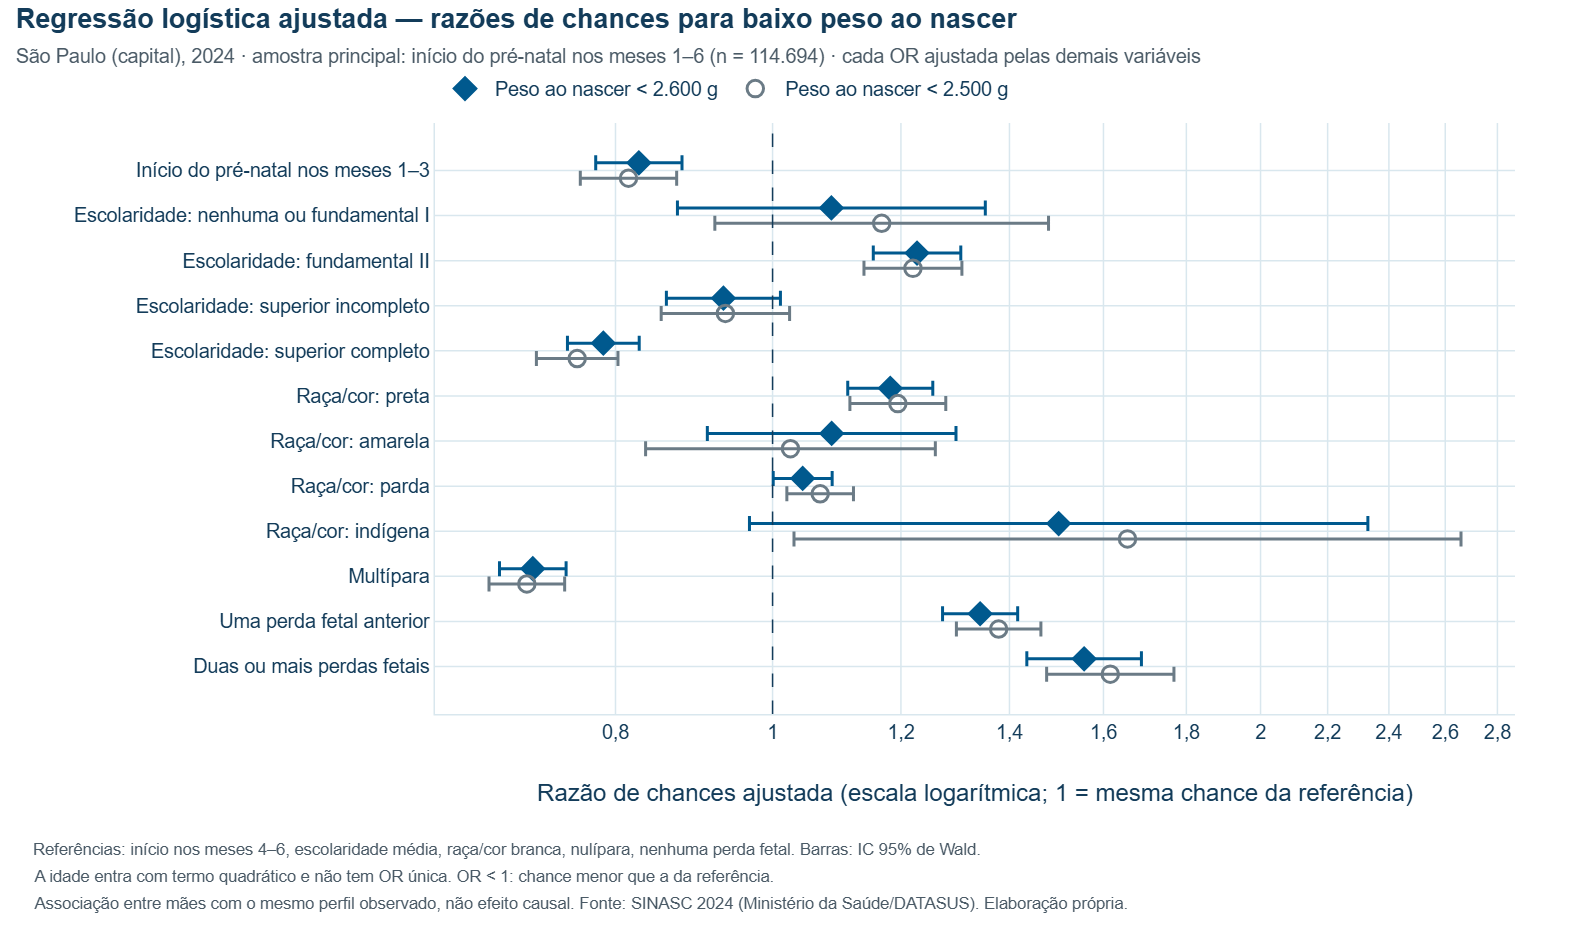

Entre mães com o mesmo perfil observado, o início nos meses 1–3 se associa a chances menores de peso < 2.600 g (OR 0,83; IC 95% 0,78 a 0,88) e a chances menores de peso < 2.500 g (OR 0,81; IC 95% 0,76 a 0,87). Sem os 94 registros com características ignoradas (casos completos), as OR ficam em 0,83 e 0,82. Na amostra de sensibilidade (comparação com os meses 4–9), a OR para < 2.600 g é 0,85 (IC 95% 0,80 a 0,90). Esse grupo de comparação, porém, só reúne gestações que chegaram ao 7º mês, o que pode deslocá-lo para gestações mais longas e mais pesadas (seleção temporal). A OR é uma associação condicional na população inteira: não estima efeito causal nem equivale à diferença de riscos do ATO no notebook 03.

In [4]:
ROTULOS = {
    X1: "Início do pré-natal nos meses 1–3",
    "ESCOLARIDADE_MAE_0-1": "Escolaridade: nenhuma ou fundamental I", "ESCOLARIDADE_MAE_2": "Escolaridade: fundamental II",
    "ESCOLARIDADE_MAE_4": "Escolaridade: superior incompleto", "ESCOLARIDADE_MAE_5": "Escolaridade: superior completo",
    "RACA_COR_MAE_2": "Raça/cor: preta", "RACA_COR_MAE_3": "Raça/cor: amarela", "RACA_COR_MAE_4": "Raça/cor: parda",
    "RACA_COR_MAE_5": "Raça/cor: indígena", "PARIDADE_CAT_1": "Multípara",
    "PERDAS_FETAIS_CAT_1": "Uma perda fetal anterior", "PERDAS_FETAIS_CAT_2_OU_MAIS": "Duas ou mais perdas fetais",
}

def or_ic(linha):
    return f"{fmt(linha['or'], 2)} ({fmt(linha['ic95_inf'], 2)} a {fmt(linha['ic95_sup'], 2)})"

def or_texto(linha):
    return f"OR {fmt(linha['or'], 2)}; IC 95% {fmt(linha['ic95_inf'], 2)} a {fmt(linha['ic95_sup'], 2)}"

# Sensibilidade por casos completos: só exclui os registros com alguma característica materna "ignorado".
completos = ~p6[["ESCOLARIDADE_MAE", "RACA_COR_MAE", "PERDAS_FETAIS_CAT"]].eq("IGNORADO").any(axis=1)
p6_cc, x_cc = p6[completos], x_p6[completos]

# P6 = amostra principal; P9 = amostra de sensibilidade (identificadores internos).
ors, diagnosticos, bruta, linhas = {}, {}, {}, []
for rotulo, desfecho in DESFECHOS.items():
    for pop, dados, x in [("P6", p6, x_p6), ("P9", p9, x_p9), ("casos completos", p6_cc, x_cc)]:
        y = dados[desfecho].to_numpy()
        ors[rotulo, pop], diagnosticos[rotulo, pop] = razoes_de_chances(
            ajustar_modelo(construir_modelo(MODELOS["M3"]), x, y), x, y)
    # Verificação numérica: com X1 sozinho, OR e EP do modelo devem coincidir com os da tabela 2×2.
    y = p6[desfecho].to_numpy()
    m1, _ = razoes_de_chances(ajustar_modelo(construir_modelo(MODELOS["M1"]), x_p6, y), x_p6, y)
    tab = pd.crosstab(p6[X1], p6[desfecho])
    a, b, c, d = (int(tab.loc[i, j]) for i, j in [(1, 1), (1, 0), (0, 1), (0, 0)])
    bruta[rotulo] = {"or_modelo": m1.loc[X1, "or"], "or_tabela": a * d / (b * c),
                     "ep_modelo": m1.loc[X1, "ep"], "ep_tabela": np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)}
    linhas.append({"Desfecho": rotulo, "Casos na amostra principal": f"{fmt(y.sum())} ({fmt(100 * y.mean(), 2)}%)",
                   "Risco, meses 1–3 (%)": fmt(100 * p6.loc[p6[X1] == 1, desfecho].mean(), 2),
                   "Risco, meses 4–6 (%)": fmt(100 * p6.loc[p6[X1] == 0, desfecho].mean(), 2),
                   "OR bruta do início nos meses 1–3": or_ic(m1.loc[X1]),
                   "OR ajustada, amostra principal": or_ic(ors[rotulo, "P6"].loc[X1]),
                   "OR ajustada, amostra de sensibilidade (meses 1–3 × 4–9)": or_ic(ors[rotulo, "P9"].loc[X1]),
                   "OR ajustada, casos completos": or_ic(ors[rotulo, "casos completos"].loc[X1])})
display(pd.DataFrame(linhas).set_index("Desfecho"))

termos = list(ors["< 2.600 g", "P6"].index)
assert termos[0] == X1 and set(termos) == set(ROTULOS)
fig_or = go.Figure()
for rotulo, cor, simbolo, desloc in [("< 2.600 g", COR_T1, "diamond", -0.17), ("< 2.500 g", COR_REFERENCIA, "circle-open", 0.17)]:
    t = ors[rotulo, "P6"].loc[termos]
    fig_or.add_scatter(
        x=t["or"], y=np.arange(len(termos)) + desloc, mode="markers", name=f"Peso ao nascer {rotulo}",
        marker=dict(color=cor, symbol=simbolo, size=11, line=dict(width=2, color=cor)),
        error_x=dict(type="data", symmetric=False, array=t.ic95_sup - t["or"], arrayminus=t["or"] - t.ic95_inf,
                     thickness=2, width=5, color=cor),
        customdata=[[ROTULOS[k], or_ic(t.loc[k])] for k in termos],
        hovertemplate="<b>%{customdata[0]}</b><br>Peso ao nascer " + rotulo
                      + "<br>OR ajustada %{customdata[1]}<extra></extra>")
fig_or.add_vline(x=1, line=dict(color=COR_TEXTO, dash="dash", width=1))
layout_academico(
    fig_or, "Regressão logística ajustada — razões de chances para baixo peso ao nascer",
    f"São Paulo (capital), 2024 · amostra principal: início do pré-natal nos meses 1–6 (n = {fmt(len(p6))}) · "
    "cada OR ajustada pelas demais variáveis",
    notas=["Referências: início nos meses 4–6, escolaridade média, raça/cor branca, nulípara, nenhuma perda fetal. "
           "Barras: IC 95% de Wald.",
           "A idade entra com termo quadrático e não tem OR única. OR < 1: chance menor que a da referência.",
           "Associação entre mães com o mesmo perfil observado, não efeito causal. " + FONTE_SINASC_2024],
    nome_arquivo="nb06_razoes_de_chances", altura=620, margem_esquerda=290)
fig_or.update_xaxes(type="log", title="Razão de chances ajustada (escala logarítmica; 1 = mesma chance da referência)")
fig_or.update_yaxes(tickvals=list(range(len(termos))), ticktext=[ROTULOS[k] for k in termos], autorange="reversed")
fig_or.update_layout(legend=dict(orientation="h", x=0, y=1.02, yanchor="bottom"))
exibir_plotly(fig_or)

def leitura_or(linha):
    if linha["ic95_sup"] < 1:
        return "chances menores"
    return "chances maiores" if linha["ic95_inf"] > 1 else "chances semelhantes (o IC inclui 1)"

o26, o25, o26_p9, cc26, cc25 = (ors[k].loc[X1] for k in [
    ("< 2.600 g", "P6"), ("< 2.500 g", "P6"), ("< 2.600 g", "P9"), ("< 2.600 g", "casos completos"),
    ("< 2.500 g", "casos completos")])
display(Markdown(
    f"Entre mães com o mesmo perfil observado, o início nos meses 1–3 se associa a {leitura_or(o26)} de peso "
    f"< 2.600 g ({or_texto(o26)}) e a {leitura_or(o25)} de peso < 2.500 g ({or_texto(o25)}). "
    f"Sem os {fmt((~completos).sum())} registros com características ignoradas (casos completos), as OR ficam em "
    f"{fmt(cc26['or'], 2)} e {fmt(cc25['or'], 2)}. Na amostra de sensibilidade (comparação com os meses 4–9), a OR "
    f"para < 2.600 g é {fmt(o26_p9['or'], 2)} (IC 95% {fmt(o26_p9['ic95_inf'], 2)} a {fmt(o26_p9['ic95_sup'], 2)}). "
    "Esse grupo de comparação, porém, só reúne gestações que chegaram ao 7º mês, o que pode deslocá-lo para "
    "gestações mais longas e mais pesadas (seleção temporal). "
    "A OR é uma associação condicional na população inteira: não estima efeito causal nem equivale à diferença "
    "de riscos do ATO no notebook 03."))

### 2.1 Coeficientes estimados e equação ajustada

Os coeficientes abaixo são os mesmos que geraram as OR acima, extraídos do modelo ajustado, sem reconstrução a partir das OR arredondadas. A equação aparece também com a idade em anos, desfazendo a padronização.

In [5]:
# Coeficientes efetivamente estimados: o mesmo ajuste da seção 1 (mesmos dados, algoritmo determinístico).
from scipy.special import expit
from src.logistica_desfecho import NUMERICAS, coeficientes_modelo, preditor_linear_escala_original

ORDEM_DESFECHOS = ["< 2.500 g", "< 2.600 g"]   # Y2500: desfecho do estudo (OMS); Y2600: sensibilidade do ponto de corte
modelos_m3, coefs, erros_equacao = {}, {}, {}
for rotulo in ORDEM_DESFECHOS:
    modelos_m3[rotulo] = m = ajustar_modelo(construir_modelo(MODELOS["M3"]), x_p6, p6[DESFECHOS[rotulo]].to_numpy())
    coefs[rotulo] = c = coeficientes_modelo(m)
    # Mesmos coeficientes que geraram as OR publicadas na seção 2.
    assert np.allclose(c.loc[ors[rotulo, "P6"].index, "coef_desenho"], ors[rotulo, "P6"].coef, rtol=0, atol=1e-10)
    eta = preditor_linear_escala_original(c, x_p6)   # só a tabela de coeficientes, sem o pipeline
    erros_equacao[rotulo] = max(float(np.abs(eta - m.decision_function(x_p6)).max()),
                                float(np.abs(expit(eta) - m.predict_proba(x_p6)[:, 1]).max()))

def num(v):
    return fmt(v, 6) if 0 < abs(v) < 0.01 else fmt(v, 4)

colunas = {}
for rotulo in ORDEM_DESFECHOS:
    c = coefs[rotulo]
    colunas[(f"Peso {rotulo}", "β (escala do modelo)")] = c.coef_desenho.map(num)
    colunas[(f"Peso {rotulo}", "OR = exp(β)")] = ["—" if t in ("Intercepto", *NUMERICAS) else fmt(np.exp(v), 2)
                                                  for t, v in c.coef_desenho.items()]
    colunas[(f"Peso {rotulo}", "b (idade em anos)")] = [num(b) if t in ("Intercepto", *NUMERICAS) else "= β"
                                                        for t, b in c.coef_original.items()]
tabela_coef = pd.DataFrame(colunas)
tabela_coef.index = pd.Index(coefs["< 2.500 g"].rotulo, name="Termo")
display(tabela_coef)

escala = coefs["< 2.500 g"].loc[list(NUMERICAS), ["media_padronizacao", "dp_padronizacao"]]
assert np.array_equal(escala, coefs["< 2.600 g"].loc[list(NUMERICAS), ["media_padronizacao", "dp_padronizacao"]])
(mu1, s1), (mu2, s2) = escala.to_numpy()

SIMBOLOS = {X1: "X_1", "IDADEMAE_NUM": r"\text{idade}", "IDADEMAE_QUAD": r"\text{idade}^2",
            "ESCOLARIDADE_MAE_0-1": r"E_{\text{nenh./fund.I}}", "ESCOLARIDADE_MAE_2": r"E_{\text{fund.II}}",
            "ESCOLARIDADE_MAE_4": r"E_{\text{sup.inc.}}", "ESCOLARIDADE_MAE_5": r"E_{\text{sup.comp.}}",
            "RACA_COR_MAE_2": r"R_{\text{preta}}", "RACA_COR_MAE_3": r"R_{\text{amarela}}",
            "RACA_COR_MAE_4": r"R_{\text{parda}}", "RACA_COR_MAE_5": r"R_{\text{indígena}}",
            "PARIDADE_CAT_1": r"M", "PERDAS_FETAIS_CAT_1": r"F_{\text{uma}}", "PERDAS_FETAIS_CAT_2_OU_MAIS": r"F_{\text{2+}}"}

def tex_num(v):
    return num(abs(v)).replace(".", "").replace(",", "{,}")

def ft(v, casas):  # número dentro de $...$: vírgula decimal sem o espaço que o LaTeX põe após a vírgula
    return fmt(v, casas).replace(",", "{,}")

def equacao(c):
    b = c.coef_original
    termos = [("-" if v < 0 else "+") + " " + tex_num(v) + r"\," + SIMBOLOS[t] for t, v in b.drop("Intercepto").items()]
    inicio = ("-" if b["Intercepto"] < 0 else "") + tex_num(b["Intercepto"])
    return (r"$$\begin{aligned}\hat\eta={}&" + inicio + " " + " ".join(termos[:7]) + r"\\ &" + " ".join(termos[7:])
            + r"\end{aligned}$$")

def vertice(c):
    b = c.coef_original
    return -b["IDADEMAE_NUM"] / (2 * b["IDADEMAE_QUAD"]), ("mínimo" if b["IDADEMAE_QUAD"] > 0 else "máximo")

perfil = pd.DataFrame([{X1: x1, "IDADEMAE_NUM": 30.0, "IDADEMAE_QUAD": 900.0, "ESCOLARIDADE_MAE": "3",
                        "RACA_COR_MAE": "1", "PARIDADE_CAT": "0", "PERDAS_FETAIS_CAT": "0"} for x1 in (1, 0)])
eta_perfil = modelos_m3["< 2.500 g"].decision_function(perfil[list(PREDITORES_M3)])
(v25, tipo25), (v26, tipo26) = vertice(coefs["< 2.500 g"]), vertice(coefs["< 2.600 g"])
display(Markdown(
    f"Padronização ajustada na amostra principal: $z^{{(1)}}=(\\text{{idade}}-{ft(mu1, 3)})/{ft(s1, 3)}$ e "
    f"$z^{{(2)}}=(\\text{{idade}}^2-{ft(mu2, 2)})/{ft(s2, 2)}$. Com a idade em anos, as equações estimadas são:\n\n"
    f"**Peso < 2.500 g**\n\n{equacao(coefs['< 2.500 g'])}\n\n**Peso < 2.600 g**\n\n{equacao(coefs['< 2.600 g'])}\n\n"
    f"e $\\hat p=1/(1+e^{{-\\hat\\eta}})$. Mantidas as demais variáveis, o logit previsto atinge o {tipo25} aos "
    f"{fmt(v25, 1)} anos (< 2.500 g) e o {tipo26} aos {fmt(v26, 1)} anos (< 2.600 g); por isso a idade entra com termo "
    "quadrático e não tem OR única. **Exemplo** (< 2.500 g): mãe de 30 anos, escolaridade média, branca, nulípara, sem "
    f"perdas fetais. Com início nos meses 1–3, $\\hat\\eta={ft(eta_perfil[0], 3)}$ e $\\hat p={ft(100 * expit(eta_perfil[0]), 1)}\\%$. "
    f"Com início nos meses 4–6, $\\hat\\eta={ft(eta_perfil[1], 3)}$ e $\\hat p={ft(100 * expit(eta_perfil[1]), 1)}\\%$. "
    "As chances diferem pelo fator exp(β₁), a OR de X1. A diferença em probabilidade muda com o perfil e é uma "
    "associação condicional, não um efeito causal."))
print(f"Equação conferida: com só os coeficientes da tabela, o logit e a probabilidade reproduzem o pipeline "
      f"(maior diferença: {max(erros_equacao.values()):.1e}).")

Peso < 2.500 g              \
                                       β (escala do modelo) OR = exp(β)   
Termo                                                                     
Intercepto                                          -2,0544           —   
Idade (padronizada)                                 -0,6016           —   
Idade² (padronizada)                                 0,6974           —   
X1: início nos meses 1–3                            -0,2047        0,81   
Escolaridade: nenhuma ou fundamental I               0,1550        1,17   
Escolaridade: fundamental II                         0,1994        1,22   
Escolaridade: superior incompleto                   -0,0670        0,94   
Escolaridade: superior completo                     -0,2775        0,76   
Raça/cor: preta                                      0,1779        1,19   
Raça/cor: amarela                                    0,0254        1,03   
Raça/cor: parda                                      0,0676        1,07   
Raça/cor: indígena                                   0,5042        1,66   
Paridade: multípara                                 -0,3491        0,71   
Perdas fetais: uma                                   0,3211        1,38   
Perdas fetais: duas ou mais                          0,4797        1,62   

                                                               Peso < 2.600 g  \
                                       b (idade em anos) β (escala do modelo)   
Termo                                                                           
Intercepto                                       -0,9947              -1,7563   
Idade (padronizada)                              -0,0906              -0,5729   
Idade² (padronizada)                            0,001768               0,6587   
X1: início nos meses 1–3                             = β              -0,1900   
Escolaridade: nenhuma ou fundamental I               = β               0,0835   
Escolaridade: fundamental II                         = β               0,2052   
Escolaridade: superior incompleto                    = β              -0,0698   
Escolaridade: superior completo                      = β              -0,2404   
Raça/cor: preta                                      = β               0,1672   
Raça/cor: amarela                                    = β               0,0839   
Raça/cor: parda                                      = β               0,0427   
Raça/cor: indígena                                   = β               0,4064   
Paridade: multípara                                  = β              -0,3406   
Perdas fetais: uma                                   = β               0,2948   
Perdas fetais: duas ou mais                          = β               0,4425   

                                                                      
                                       OR = exp(β) b (idade em anos)  
Termo                                                                 
Intercepto                                       —           -0,7345  
Idade (padronizada)                              —           -0,0862  
Idade² (padronizada)                             —          0,001670  
X1: início nos meses 1–3                      0,83               = β  
Escolaridade: nenhuma ou fundamental I        1,09               = β  
Escolaridade: fundamental II                  1,23               = β  
Escolaridade: superior incompleto             0,93               = β  
Escolaridade: superior completo               0,79               = β  
Raça/cor: preta                               1,18               = β  
Raça/cor: amarela                             1,09               = β  
Raça/cor: parda                               1,04               = β  
Raça/cor: indígena                            1,50               = β  
Paridade: multípara                           0,71               = β  
Perdas fetais: uma                            1,34               = β  
Perdas fetais: duas ou mais 

Padronização ajustada na amostra principal: $z^{(1)}=(\text{idade}-29{,}143)/6{,}643$ e $z^{(2)}=(\text{idade}^2-893{,}44)/394{,}54$. Com a idade em anos, as equações estimadas são:

**Peso < 2.500 g**

$$\begin{aligned}\hat\eta={}&-0{,}9947 - 0{,}0906\,\text{idade} + 0{,}001768\,\text{idade}^2 - 0{,}2047\,X_1 + 0{,}1550\,E_{\text{nenh./fund.I}} + 0{,}1994\,E_{\text{fund.II}} - 0{,}0670\,E_{\text{sup.inc.}} - 0{,}2775\,E_{\text{sup.comp.}}\\ &+ 0{,}1779\,R_{\text{preta}} + 0{,}0254\,R_{\text{amarela}} + 0{,}0676\,R_{\text{parda}} + 0{,}5042\,R_{\text{indígena}} - 0{,}3491\,M + 0{,}3211\,F_{\text{uma}} + 0{,}4797\,F_{\text{2+}}\end{aligned}$$

**Peso < 2.600 g**

$$\begin{aligned}\hat\eta={}&-0{,}7345 - 0{,}0862\,\text{idade} + 0{,}001670\,\text{idade}^2 - 0{,}1900\,X_1 + 0{,}0835\,E_{\text{nenh./fund.I}} + 0{,}2052\,E_{\text{fund.II}} - 0{,}0698\,E_{\text{sup.inc.}} - 0{,}2404\,E_{\text{sup.comp.}}\\ &+ 0{,}1672\,R_{\text{preta}} + 0{,}0839\,R_{\text{amarela}} + 0{,}0427\,R_{\text{parda}} + 0{,}4064\,R_{\text{indígena}} - 0{,}3406\,M + 0{,}2948\,F_{\text{uma}} + 0{,}4425\,F_{\text{2+}}\end{aligned}$$

e $\hat p=1/(1+e^{-\hat\eta})$. Mantidas as demais variáveis, o logit previsto atinge o mínimo aos 25,6 anos (< 2.500 g) e o mínimo aos 25,8 anos (< 2.600 g); por isso a idade entra com termo quadrático e não tem OR única. **Exemplo** (< 2.500 g): mãe de 30 anos, escolaridade média, branca, nulípara, sem perdas fetais. Com início nos meses 1–3, $\hat\eta=-2{,}325$ e $\hat p=8{,}9\%$. Com início nos meses 4–6, $\hat\eta=-2{,}120$ e $\hat p=10{,}7\%$. As chances diferem pelo fator exp(β₁), a OR de X1. A diferença em probabilidade muda com o perfil e é uma associação condicional, não um efeito causal.

Equação conferida: com só os coeficientes da tabela, o logit e a probabilidade reproduzem o pipeline (maior diferença: 1.8e-15).


## 3. Peso ao nascer em gramas

O peso é medido por mês de início do pré-natal:
- A comparação principal (meses 1–3 × meses 4–6) usa a diferença de médias com IC de Welch, que não supõe variâncias iguais.
- Os meses 1–6 entram numa ANOVA de Welch.
- Os meses 7–9 e os 993 registros sem mês válido (889 com MESPRENAT vazio e 104 com o código 99, "ignorado") ficam fora das comparações e aparecem só para descrever a seleção.

,n,Média (IC 95%),DP,P10,P25,Mediana,P75,P90,% < 2.500 g,% < 2.600 g
Início do pré-natal (peso em gramas),,,,,,,,,,
Meses 1–3,104.576,3.155 (3.152 a 3.158),522,2.560,2.890,3.190,3.480,3.746,"8,41","11,10"
Meses 4–6,10.118,3.131 (3.121 a 3.142),555,2.480,2.845,3.173,3.480,3.760,"10,41","13,39"
Mês 1,35.224,3.165 (3.160 a 3.170),510,2.580,2.900,3.200,3.485,3.740,"7,93","10,58"
Mês 2,54.444,3.150 (3.146 a 3.154),526,2.555,2.884,3.185,3.476,3.750,"8,52","11,27"
Mês 3,14.908,3.147 (3.138 a 3.156),535,2.530,2.875,3.180,3.490,3.759,"9,13","11,70"
Mês 4,5.366,3.146 (3.131 a 3.161),544,2.515,2.865,3.185,3.480,3.766,"9,50","12,47"
Mês 5,3.005,3.120 (3.099 a 3.140),571,2.450,2.824,3.170,3.490,3.765,"11,41","14,41"
Mês 6,1.747,3.107 (3.081 a 3.133),559,2.442,2.810,3.140,3.462,3.731,"11,45","14,48"
Meses 7–9 (só na amostra de sensibilidade),1.735,3.165 (3.140 a 3.190),525,2.559,2.865,3.200,3.495,3.780,"8,65","11,53"


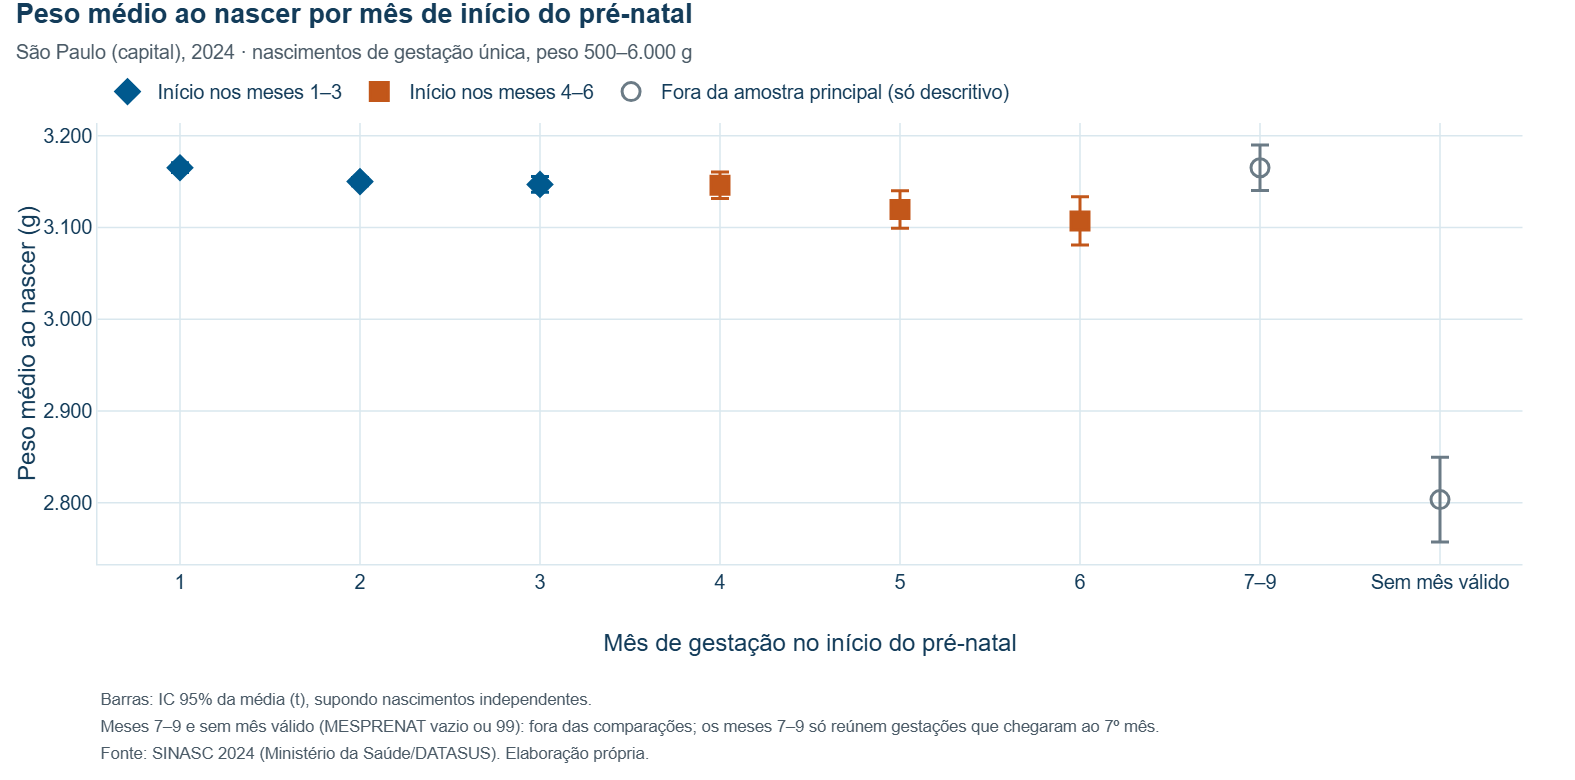

Nascidos de mães com início nos meses 1–3 pesaram em média 23 g a mais que os de início nos meses 4–6 (IC 95% de Welch: 12 a 34 g). A ANOVA de Welch dos meses 1–6 dá F(5; 10.456) = 9,3, p < 0,001, com médias mensais de 3.107 a 3.165 g; com mais de 100 mil nascimentos, o tamanho da diferença em gramas pesa mais que o valor-p. Os 993 registros sem mês de início válido (910 deles com zero consulta de pré-natal registrada) têm média de 2.804 g e 25,6% abaixo de 2.500 g, contra 8,6% na amostra principal: excluí-los pode introduzir viés de seleção, de direção desconhecida.

In [6]:
partes = [
    (p6.peso_num, np.where(p6[X1] == 1, "Meses 1–3", "Meses 4–6")),
    (p6.peso_num, "Mês " + p6.mesprenat_num.astype(int).astype(str)),
    (p9.loc[p9.mesprenat_num >= 7, "peso_num"], "Meses 7–9 (só na amostra de sensibilidade)"),
    (sem_mes.peso_num, "Sem mês válido (vazio ou 99)"),
]
resumo = pd.concat([resumir_peso(peso, pd.Series(grupo, index=peso.index)) for peso, grupo in partes])
ORDEM = ["Meses 1–3", "Meses 4–6", *(f"Mês {m}" for m in range(1, 7)), "Meses 7–9 (só na amostra de sensibilidade)",
         "Sem mês válido (vazio ou 99)"]
resumo = resumo.loc[ORDEM]
display(pd.DataFrame({
    "n": resumo.n.map(fmt),
    "Média (IC 95%)": [f"{fmt(r.media)} ({fmt(r.ic95_inf)} a {fmt(r.ic95_sup)})" for r in resumo.itertuples()],
    "DP": resumo.dp.map(fmt), "P10": resumo.p10.map(fmt), "P25": resumo.p25.map(fmt),
    "Mediana": resumo.mediana.map(fmt), "P75": resumo.p75.map(fmt), "P90": resumo.p90.map(fmt),
    "% < 2.500 g": resumo.pct_menor_2500.map(lambda v: fmt(v, 2)),
    "% < 2.600 g": resumo.pct_menor_2600.map(lambda v: fmt(v, 2)),
}, index=pd.Index(ORDEM, name="Início do pré-natal (peso em gramas)")))

welch = comparar_medias_welch(p6.loc[p6[X1] == 1, "peso_num"].to_numpy(), p6.loc[p6[X1] == 0, "peso_num"].to_numpy())
anova = anova_welch({m: p6.loc[p6.mesprenat_num == m, "peso_num"].to_numpy() for m in range(1, 7)})

fig_peso = go.Figure()
for nome, rotulos, xs, cor, simbolo in [
        ("Início nos meses 1–3", ["Mês 1", "Mês 2", "Mês 3"], ["1", "2", "3"], COR_T1, "diamond"),
        ("Início nos meses 4–6", ["Mês 4", "Mês 5", "Mês 6"], ["4", "5", "6"], COR_T0, "square"),
        ("Fora da amostra principal (só descritivo)", ["Meses 7–9 (só na amostra de sensibilidade)", "Sem mês válido (vazio ou 99)"], ["7–9", "Sem mês válido"],
         COR_REFERENCIA,
         "circle-open")]:
    r = resumo.loc[rotulos]
    fig_peso.add_scatter(
        x=xs, y=r.media, mode="markers", name=nome,
        marker=dict(color=cor, symbol=simbolo, size=12, line=dict(width=2, color=cor)),
        error_y=dict(type="data", symmetric=False, array=r.ic95_sup - r.media, arrayminus=r.media - r.ic95_inf,
                     thickness=2, width=6, color=cor),
        customdata=[[fmt(v.n), fmt(v.ic95_inf), fmt(v.ic95_sup), fmt(v.pct_menor_2500, 2)] for v in r.itertuples()],
        hovertemplate=("<b>%{x}</b><br>média %{y:.0f} g (IC 95% %{customdata[1]} a %{customdata[2]})<br>"
                       "n %{customdata[0]} · %{customdata[3]}% < 2.500 g<extra></extra>"))
layout_academico(
    fig_peso, "Peso médio ao nascer por mês de início do pré-natal",
    "São Paulo (capital), 2024 · nascimentos de gestação única, peso 500–6.000 g",
    notas=["Barras: IC 95% da média (t), supondo nascimentos independentes.",
           "Meses 7–9 e sem mês válido (MESPRENAT vazio ou 99): fora das comparações; os meses 7–9 só reúnem gestações "
           "que chegaram ao 7º mês.",
           FONTE_SINASC_2024],
    nome_arquivo="nb06_peso_por_mes", altura=520)
fig_peso.update_xaxes(title="Mês de gestação no início do pré-natal", type="category",
                      categoryorder="array", categoryarray=["1", "2", "3", "4", "5", "6", "7–9", "Sem mês válido"])
fig_peso.update_yaxes(title="Peso médio ao nascer (g)", tickformat=",.0f")
fig_peso.update_layout(legend=dict(orientation="h", x=0, y=1.02, yanchor="bottom"))
exibir_plotly(fig_peso)

def valor_p(p):
    return "p < 0,001" if p < 0.001 else f"p = {fmt(p, 3)}"

sentido = "a mais" if welch["diferenca"] > 0 else "a menos"
medias = resumo.loc[[f"Mês {m}" for m in range(1, 7)], "media"]
ign, total = resumo.loc["Sem mês válido (vazio ou 99)"], 100 * p6.Y_2500.mean()
display(Markdown(
    f"Nascidos de mães com início nos meses 1–3 pesaram em média {fmt(abs(welch['diferenca']))} g {sentido} que os "
    f"de início nos meses 4–6 (IC 95% de Welch: {fmt(welch['ic95_inf'])} a {fmt(welch['ic95_sup'])} g). A ANOVA de "
    f"Welch dos meses 1–6 dá F({anova['gl1']}; {fmt(anova['gl2'], 0)}) = {fmt(anova['F'], 1)}, {valor_p(anova['p'])}, "
    f"com médias mensais de {fmt(medias.min())} a {fmt(medias.max())} g; com mais de 100 mil nascimentos, o tamanho "
    f"da diferença em gramas pesa mais que o valor-p. Os {fmt(ign.n)} registros sem mês de início válido "
    f"({fmt(zero_consulta)} deles com zero consulta de pré-natal registrada) têm média de {fmt(ign.media)} g e "
    f"{fmt(ign.pct_menor_2500, 1)}% abaixo de 2.500 g, contra {fmt(total, 1)}% na amostra principal: excluí-los pode introduzir "
    "viés de seleção, de direção desconhecida."))

## 4. Avaliação preditiva fora da amostra

Os quatro modelos foram fixados antes de qualquer resultado:
- **modelo de referência** (prevalência);
- **modelo com início do pré-natal**;
- **regressão logística ajustada**;
- **modelo ajustado apenas com características maternas**.

Cada nascimento é previsto por um modelo ajustado nas outras quatro dobras de uma validação cruzada estratificada (5 dobras, semente 20240925), com codificação e padronização refeitas em cada treino. Quatro medidas resumem o desempenho:
- **ROC-AUC (discriminação):** probabilidade de que, num par formado por um caso e um não caso, o caso receba o risco previsto maior. O valor 0,5 equivale ao acaso.
- **Average precision:** área sob a curva de precisão × sensibilidade. A referência é a prevalência.
- **Brier:** erro quadrático médio das probabilidades.
- **Calibração:** compara o risco previsto com a proporção observada.

É uma avaliação **retrospectiva**, com validação **interna** nos próprios nascimentos de 2024, a partir de dados registrados na Declaração de Nascido Vivo. Não é um modelo de previsão clínica prospectiva e não foi validado em outros anos ou serviços.

In [7]:
from src.logistica_desfecho import ROTULOS_MODELOS

previsoes, metricas, dobras, linhas = {}, {}, {}, []
for rotulo, desfecho in DESFECHOS.items():
    y = p6[desfecho].to_numpy()
    for nome, preditores in MODELOS.items():
        previsoes[rotulo, nome], dobras[rotulo] = prever_fora_da_amostra(construir_modelo(preditores), x_p6, y)
        m = metricas[rotulo, nome] = metricas_probabilisticas(y, previsoes[rotulo, nome])
        linhas.append({"Desfecho": f"Peso {rotulo}", "Modelo": ROTULOS_MODELOS[nome], "ROC-AUC": fmt(m["roc_auc"], 3),
                       "Average precision": fmt(m["average_precision"], 3), "Prevalência": fmt(m["prevalencia"], 3),
                       "Brier": fmt(m["brier"], 4),
                       "Previsto − observado (p.p.)": fmt(round(100 * m["dif_media_prevista_observada"], 2) + 0.0, 2),
                       "Inclinação de calibração": "—" if np.isnan(m["inclinacao_calibracao"])
                       else fmt(m["inclinacao_calibracao"], 2)})
display(pd.DataFrame(linhas).set_index(["Desfecho", "Modelo"]))

def com_sinal(valor, casas):
    return ("+" if valor > 0 else "−" if valor < 0 else "") + fmt(abs(valor), casas)

m26, m25, sem_x1 = metricas["< 2.600 g", "M3"], metricas["< 2.500 g", "M3"], metricas["< 2.600 g", "M3 sem X1"]
d_auc, d_brier = m26["roc_auc"] - sem_x1["roc_auc"], m26["brier"] - sem_x1["brier"]
ganho = "quase não melhora a previsão" if abs(d_auc) < 0.01 else "muda a previsão"
calibracao = ("próximas da calibração ideal" if abs(m26["inclinacao_calibracao"] - 1) < 0.1
              and abs(m26["dif_media_prevista_observada"]) < 0.0005 else "afastadas da calibração ideal")
display(Markdown(
    f"Fora da amostra, a regressão logística ajustada tem ROC-AUC {fmt(m26['roc_auc'], 3)} para < 2.600 g "
    f"({fmt(m25['roc_auc'], 3)} para < 2.500 g): num par com um caso e um não caso, o caso recebe o risco previsto "
    f"maior em {fmt(100 * m26['roc_auc'], 0)}% das vezes, contra 50% no modelo de referência. A average precision é "
    f"{fmt(m26['average_precision'], 3)}, para uma prevalência de {fmt(m26['prevalencia'], 3)}. Acrescentar o início do "
    f"pré-natal ao modelo ajustado apenas com características maternas muda a AUC em {com_sinal(d_auc, 3)} e o Brier "
    f"em {com_sinal(d_brier, 5)}: o início do pré-natal se associa ao desfecho (seção 2), mas {ganho}. As previsões "
    f"estão {calibracao} (inclinação {fmt(m26['inclinacao_calibracao'], 2)}, ideal 1; risco médio previsto menos "
    f"observado: {fmt(round(100 * m26['dif_media_prevista_observada'], 2) + 0.0, 2)} p.p.). Capacidade preditiva, alta "
    "ou baixa, não indica efeito causal."))

# Curvas das figuras seguintes: as mesmas previsões fora da amostra da tabela, sem novo ajuste.
CURVAS = [("M1", COR_T0, "dot"), ("M3", COR_T1, "solid"), ("M3 sem X1", COR_REFERENCIA, "dash")]
y26 = p6.Y_2600.to_numpy()
COR_ACASO = "#9AA5AD"

def reduzir(x, y, n=200):
    i = np.unique(np.linspace(0, len(x) - 1, min(n, len(x))).astype(int))
    return x[i], y[i]

ROC-AUC  \
Desfecho       Modelo                                                       
Peso < 2.600 g Modelo de referência (prevalência)                   0,500   
               Modelo com início do pré-natal                       0,508   
               Regressão logística ajustada (pré-natal e carac...   0,565   
               Modelo ajustado apenas com características mate...   0,563   
Peso < 2.500 g Modelo de referência (prevalência)                   0,500   
               Modelo com início do pré-natal                       0,508   
               Regressão logística ajustada (pré-natal e carac...   0,571   
               Modelo ajustado apenas com características mate...   0,569   

                                                                  Average precision  \
Desfecho       Modelo                                                                 
Peso < 2.600 g Modelo de referência (prevalência)                             0,113   
               Modelo com início do pré-natal                                 0,116   
               Regressão logística ajustada (pré-natal e carac...             0,138   
               Modelo ajustado apenas com características mate...             0,137   
Peso < 2.500 g Modelo de referência (prevalência)                             0,086   
               Modelo com início do pré-natal                                 0,089   
               Regressão logística ajustada (pré-natal e carac...             0,107   
               Modelo ajustado apenas com características mate...             0,106   

                                                                  Prevalência  \
Desfecho       Modelo                                                           
Peso < 2.600 g Modelo de referência (prevalência)                       0,113   
               Modelo com início do pré-natal                           0,113   
               Regressão logística ajustada (pré-natal e carac...       0,113   
               Modelo ajustado apenas com características mate...       0,113   
Peso < 2.500 g Modelo de referência (prevalência)                       0,086   
               Modelo com início do pré-natal                           0,086   
               Regressão logística ajustada (pré-natal e carac...       0,086   
               Modelo ajustado apenas com características mate...       0,086   

                                                                    Brier  \
Desfecho       Modelo                                                       
Peso < 2.600 g Modelo de referência (prevalência)                  0,1002   
               Modelo com início do pré-natal                      0,1002   
               Regressão logística ajustada (pré-natal e carac...  0,0997   
               Modelo ajustado apenas com características mate...  0,0998   
Peso < 2.500 g Modelo de referência (prevalência)                  0,0785   
               Modelo com início do pré-natal                      0,0785   
               Regressão logística ajustada (pré-natal e carac...  0,0781   
               Modelo ajustado apenas com características mate...  0,0782   

                                                                  Previsto − observado (p.p.)  \
Desfecho       Modelo                                                                           
Peso < 2.600 g Modelo de referência (prevalência)                                        0,00   
               Modelo com início do pré-natal                                            0,00   
               Regressão logística ajustada (pré-natal e carac...                        0,00   
               Modelo ajustado apenas com características mate...                        0,00   
Peso < 2.500 g Modelo de referência (prevalência)                                        0,00   
               Modelo com início do pré-natal                                            0,00   
               Regressão logística ajustada (pré-natal e carac... 

Fora da amostra, a regressão logística ajustada tem ROC-AUC 0,565 para < 2.600 g (0,571 para < 2.500 g): num par com um caso e um não caso, o caso recebe o risco previsto maior em 56% das vezes, contra 50% no modelo de referência. A average precision é 0,138, para uma prevalência de 0,113. Acrescentar o início do pré-natal ao modelo ajustado apenas com características maternas muda a AUC em +0,002 e o Brier em −0,00003: o início do pré-natal se associa ao desfecho (seção 2), mas quase não melhora a previsão. As previsões estão próximas da calibração ideal (inclinação 0,97, ideal 1; risco médio previsto menos observado: 0,00 p.p.). Capacidade preditiva, alta ou baixa, não indica efeito causal.

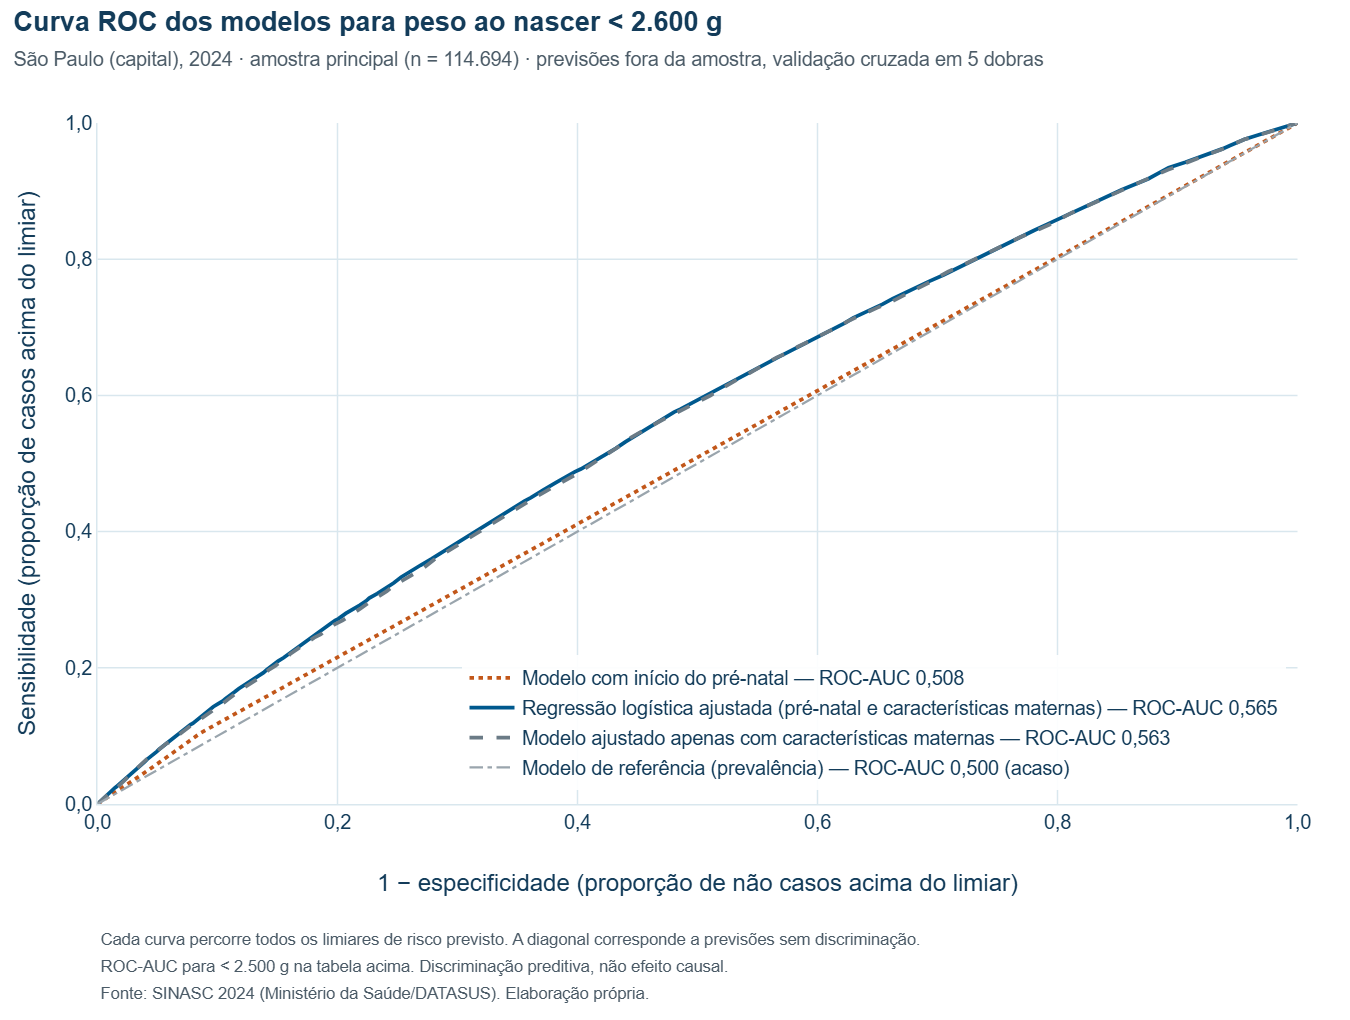

In [8]:
# Figura A — curva ROC (peso < 2.600 g), com a ROC-AUC de cada modelo na legenda.
fig_roc = go.Figure()
for nome, cor, traco in CURVAS:
    fpr, tpr = reduzir(*roc_curve(y26, previsoes["< 2.600 g", nome])[:2])
    fig_roc.add_scatter(
        x=fpr, y=tpr, mode="lines", line=dict(color=cor, dash=traco, width=2.5),
        name=f"{ROTULOS_MODELOS[nome]} — ROC-AUC {fmt(metricas['< 2.600 g', nome]['roc_auc'], 3)}",
        hovertemplate=ROTULOS_MODELOS[nome] + "<br>1 − especificidade %{x:.2f}<br>sensibilidade %{y:.2f}<extra></extra>")
fig_roc.add_scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(color=COR_ACASO, dash="dashdot", width=1.5),
                    name=f"{ROTULOS_MODELOS['M0']} — ROC-AUC {fmt(metricas['< 2.600 g', 'M0']['roc_auc'], 3)} (acaso)",
                    hoverinfo="skip")
layout_academico(
    fig_roc, "Curva ROC dos modelos para peso ao nascer < 2.600 g",
    f"São Paulo (capital), 2024 · amostra principal (n = {fmt(len(p6))}) · previsões fora da amostra, validação cruzada em 5 dobras",
    notas=["Cada curva percorre todos os limiares de risco previsto. A diagonal corresponde a previsões sem discriminação.",
           "ROC-AUC para < 2.500 g na tabela acima. Discriminação preditiva, não efeito causal.", FONTE_SINASC_2024],
    nome_arquivo="nb06_roc", largura=900, altura=680)
fig_roc.update_xaxes(title="1 − especificidade (proporção de não casos acima do limiar)", range=[0, 1], tickformat=".1f")
fig_roc.update_yaxes(title="Sensibilidade (proporção de casos acima do limiar)", range=[0, 1], tickformat=".1f")
fig_roc.update_layout(legend=dict(x=0.99, y=0.02, xanchor="right", yanchor="bottom", bgcolor="rgba(255,255,255,0.9)"))
exibir_plotly(fig_roc)

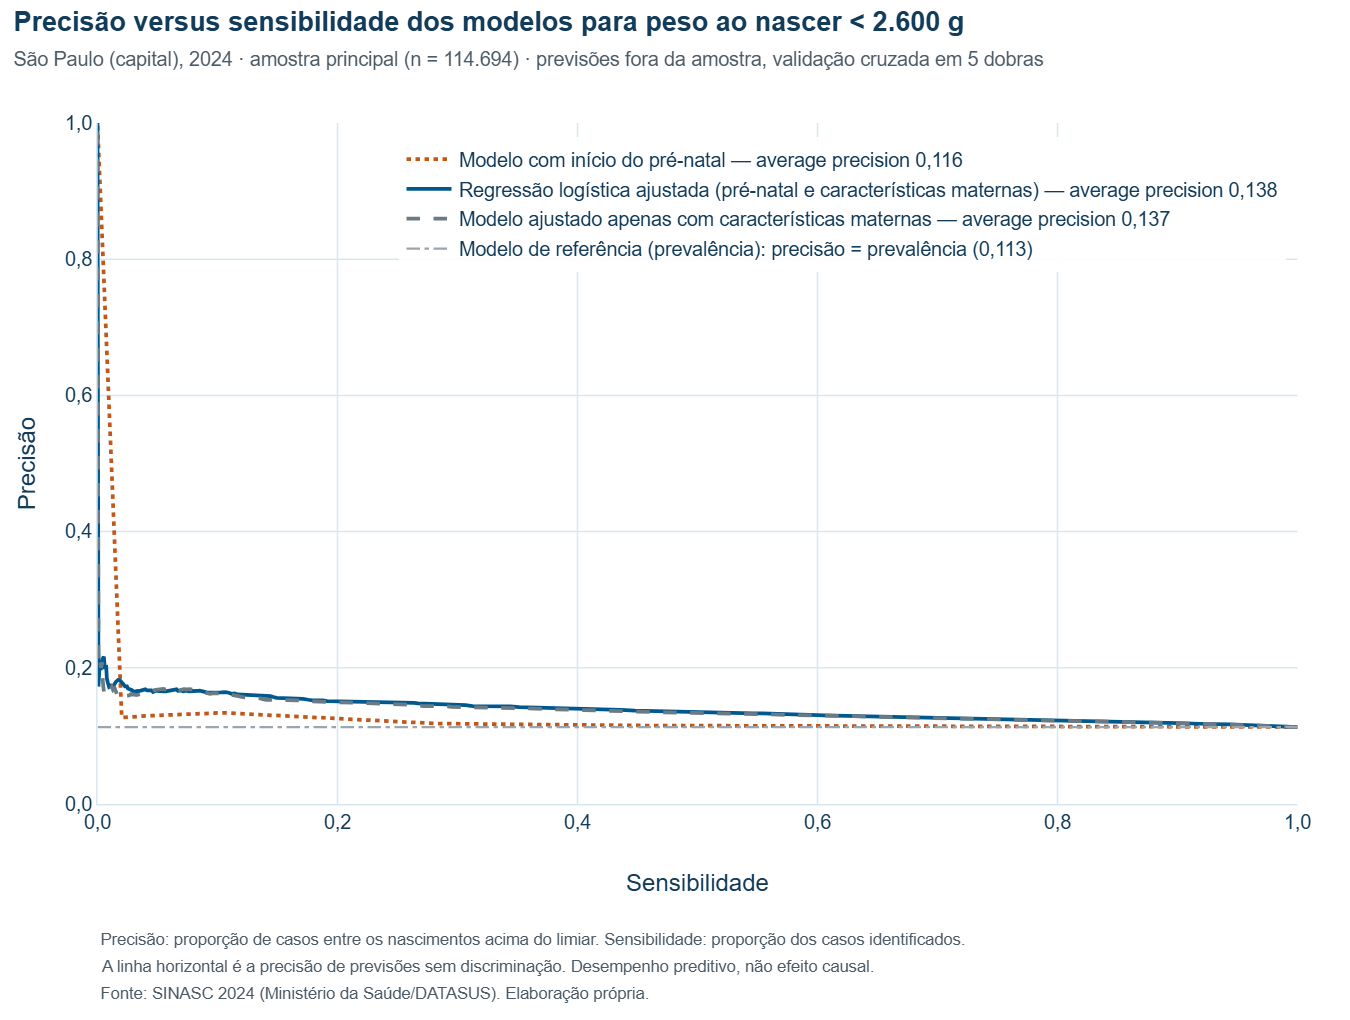

In [9]:
# Figura B — precisão × sensibilidade (peso < 2.600 g); a referência sem discriminação é a prevalência.
fig_pr = go.Figure()
for nome, cor, traco in CURVAS:
    precisao, sensibilidade = precision_recall_curve(y26, previsoes["< 2.600 g", nome])[:2]
    sensibilidade, precisao = reduzir(sensibilidade, precisao)
    fig_pr.add_scatter(
        x=sensibilidade, y=precisao, mode="lines", line=dict(color=cor, dash=traco, width=2.5),
        name=f"{ROTULOS_MODELOS[nome]} — average precision {fmt(metricas['< 2.600 g', nome]['average_precision'], 3)}",
        hovertemplate=ROTULOS_MODELOS[nome] + "<br>sensibilidade %{x:.2f}<br>precisão %{y:.2f}<extra></extra>")
prevalencia = y26.mean()
fig_pr.add_scatter(x=[0, 1], y=[prevalencia, prevalencia], mode="lines",
                   line=dict(color=COR_ACASO, dash="dashdot", width=1.5), hoverinfo="skip",
                   name=f"{ROTULOS_MODELOS['M0']}: precisão = prevalência ({fmt(prevalencia, 3)})")
layout_academico(
    fig_pr, "Precisão versus sensibilidade dos modelos para peso ao nascer < 2.600 g",
    f"São Paulo (capital), 2024 · amostra principal (n = {fmt(len(p6))}) · previsões fora da amostra, validação cruzada em 5 dobras",
    notas=["Precisão: proporção de casos entre os nascimentos acima do limiar. Sensibilidade: proporção dos casos identificados.",
           "A linha horizontal é a precisão de previsões sem discriminação. Desempenho preditivo, não efeito causal.",
           FONTE_SINASC_2024],
    nome_arquivo="nb06_precisao_sensibilidade", largura=900, altura=680)
fig_pr.update_xaxes(title="Sensibilidade", range=[0, 1], tickformat=".1f")
fig_pr.update_yaxes(title="Precisão", range=[0, 1], tickformat=".1f")
fig_pr.update_layout(legend=dict(x=0.99, y=0.98, xanchor="right", yanchor="top", bgcolor="rgba(255,255,255,0.9)"))
exibir_plotly(fig_pr)

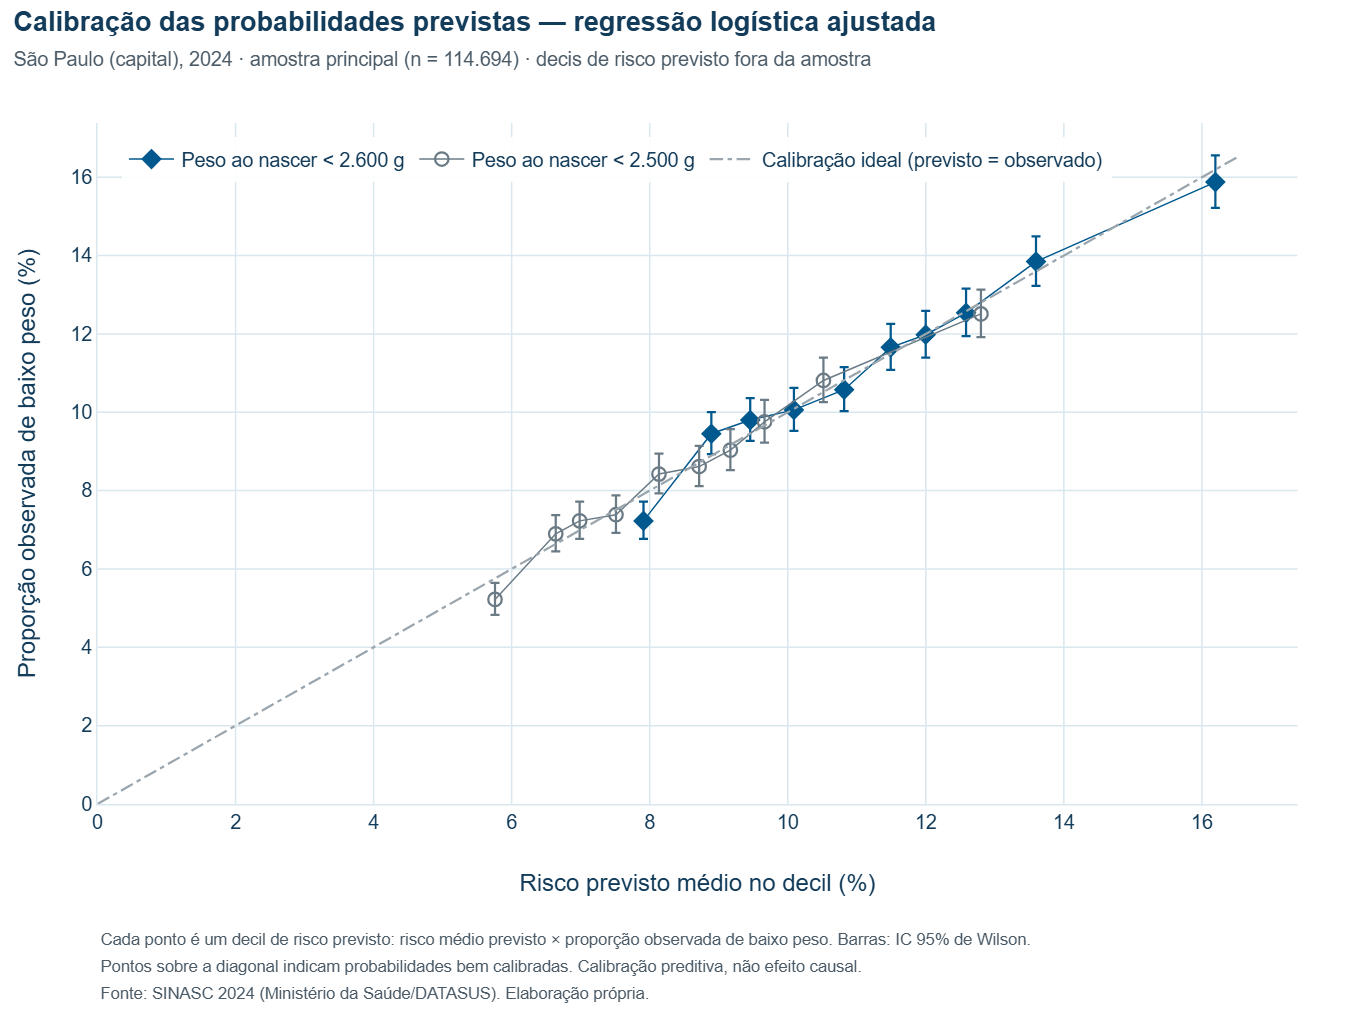

In [10]:
# Figura C — calibração por decis de risco previsto, com IC 95% de Wilson, para os dois limites de peso.
fig_cal = go.Figure()
limite = 0
for rotulo, cor, simbolo in [("< 2.600 g", COR_T1, "diamond"), ("< 2.500 g", COR_REFERENCIA, "circle-open")]:
    curva = curva_calibracao(p6[DESFECHOS[rotulo]].to_numpy(), previsoes[rotulo, "M3"])
    limite = max(limite, 100 * curva[["previsto", "ic95_sup"]].to_numpy().max())
    fig_cal.add_scatter(
        x=100 * curva.previsto, y=100 * curva.observado, mode="markers+lines", name=f"Peso ao nascer {rotulo}",
        marker=dict(color=cor, symbol=simbolo, size=9, line=dict(width=1.5, color=cor)), line=dict(color=cor, width=1),
        error_y=dict(type="data", symmetric=False, array=100 * (curva.ic95_sup - curva.observado),
                     arrayminus=100 * (curva.observado - curva.ic95_inf), thickness=1.5, width=3, color=cor),
        hovertemplate="risco previsto médio %{x:.1f}%<br>proporção observada %{y:.1f}%<extra>" + rotulo + "</extra>")
fig_cal.add_scatter(x=[0, limite], y=[0, limite], mode="lines", name="Calibração ideal (previsto = observado)",
                    line=dict(color=COR_ACASO, dash="dashdot", width=1.5), hoverinfo="skip")
layout_academico(
    fig_cal, "Calibração das probabilidades previstas — regressão logística ajustada",
    f"São Paulo (capital), 2024 · amostra principal (n = {fmt(len(p6))}) · decis de risco previsto fora da amostra",
    notas=["Cada ponto é um decil de risco previsto: risco médio previsto × proporção observada de baixo peso. Barras: IC 95% de Wilson.",
           "Pontos sobre a diagonal indicam probabilidades bem calibradas. Calibração preditiva, não efeito causal.",
           FONTE_SINASC_2024],
    nome_arquivo="nb06_calibracao", largura=900, altura=680)
fig_cal.update_xaxes(title="Risco previsto médio no decil (%)", range=[0, limite * 1.05])
fig_cal.update_yaxes(title="Proporção observada de baixo peso (%)", range=[0, limite * 1.05])
fig_cal.update_layout(legend=dict(x=0.02, y=0.98, xanchor="left", yanchor="top", bgcolor="rgba(255,255,255,0.9)"))
exibir_plotly(fig_cal)

## 5. Interpretabilidade: valores SHAP

**Por quê.** A OR (seção 2) compara as chances entre os níveis de uma variável, mas não diz quanto essa variável pesa nas previsões do modelo para a população. Esse peso depende também de quantas mães estão em cada nível. A análise SHAP decompõe cada previsão em contribuições aditivas das variáveis e não atribui interpretação causal a essas contribuições.

**Como.**
- **Modelo explicado:** a regressão logística ajustada do **desfecho**, ajustada na amostra principal inteira (seção 2.1). A prioridade é < 2.500 g, e < 2.600 g entra para comparação. Não é o escore de propensão do notebook 03.
- **Método:** `shap.LinearExplainer`, com perturbação intervencional e fundo igual à amostra principal inteira. Num modelo linear no logit, o valor SHAP é exato: $\phi_j(x)=\beta_j\,(x_j-\bar x_j)$ e $\phi_0+\sum_j\phi_j(x)=\hat\eta(x)$, em que $\phi_0$ é o logit médio previsto. A decomposição em forma fechada é recalculada e comparada com a da biblioteca. A padronização da idade não altera $\phi$.
- **Escala:** **log-odds** (logit). As contribuições se somam no logit, e não na probabilidade: não são pontos percentuais nem diferenças de risco. $\phi_0$ convertido em probabilidade não é a prevalência, porque a transformação do logit médio não é a média das probabilidades.
- **Universo e amostra:** o universo é a amostra principal (114.694 nascimentos), que também serve de fundo. As contribuições são calculadas em 10.000 nascimentos sorteados sem reposição (semente 20240925), e a importância é recalculada no universo para conferir o sorteio.
- **Agregação:** idade e idade² são somadas linha a linha, porque a idade só tem sentido em conjunto. O mesmo vale para os indicadores de uma mesma categórica. A importância global é a média de $|\phi|$ da variável agregada, calculada depois da soma.

**Figuras.** A importância global compara os dois limites de peso. As contribuições por nível aparecem em duas figuras separadas: uma para o início do pré-natal e as variáveis categóricas, outra para a idade.

**Como ler.** A importância SHAP mostra quanto uma variável moveu as previsões deste modelo em torno do logit médio. Ela depende do coeficiente e da distribuição da variável. Não é efeito causal, não é significância estatística e não mede relevância clínica.

SHAP conferido: shap 0.51.0, LinearExplainer (perturbação intervencional), escala log-odds. Universo e fundo: amostra principal, 114.694 nascimentos; amostra de 10.000 sorteada sem reposição (semente 20240925). Maior diferença entre a biblioteca e a decomposição exata, erro de reconstrução do logit e erro da agregação: 4.4e-16.


Peso < 2.500 g                            \
                         amostra (10.000) amostra principal inteira   
Média de |φ| (log-odds)                                               
Paridade                            0,167                     0,167   
Escolaridade                        0,125                     0,124   
Perdas fetais anteriores            0,122                     0,122   
Idade (idade + idade²)              0,093                     0,093   
Raça/cor                            0,045                     0,045   
Início do pré-natal (X1)            0,033                     0,033   

                           Peso < 2.600 g                            
                         amostra (10.000) amostra principal inteira  
Média de |φ| (log-odds)                                              
Paridade                            0,163                     0,163  
Escolaridade                        0,111                     0,110  
Perdas fetais anteriores            0,112                     0,112  
Idade (idade + idade²)              0,085                     0,086  
Raça/cor                            0,034                     0,034  
Início do pré-natal (X1)            0,030                     0,031

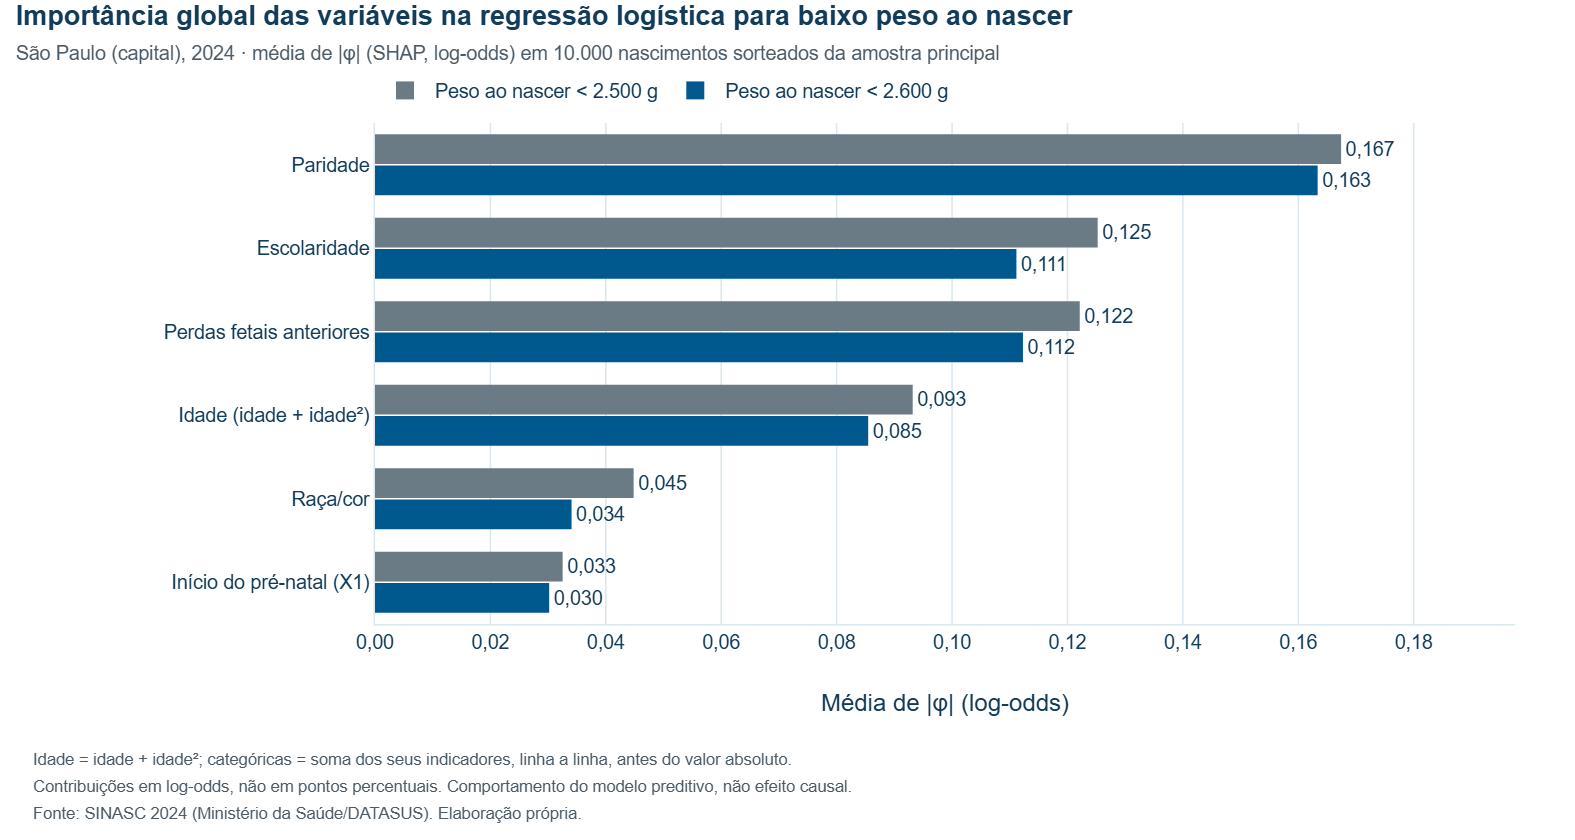

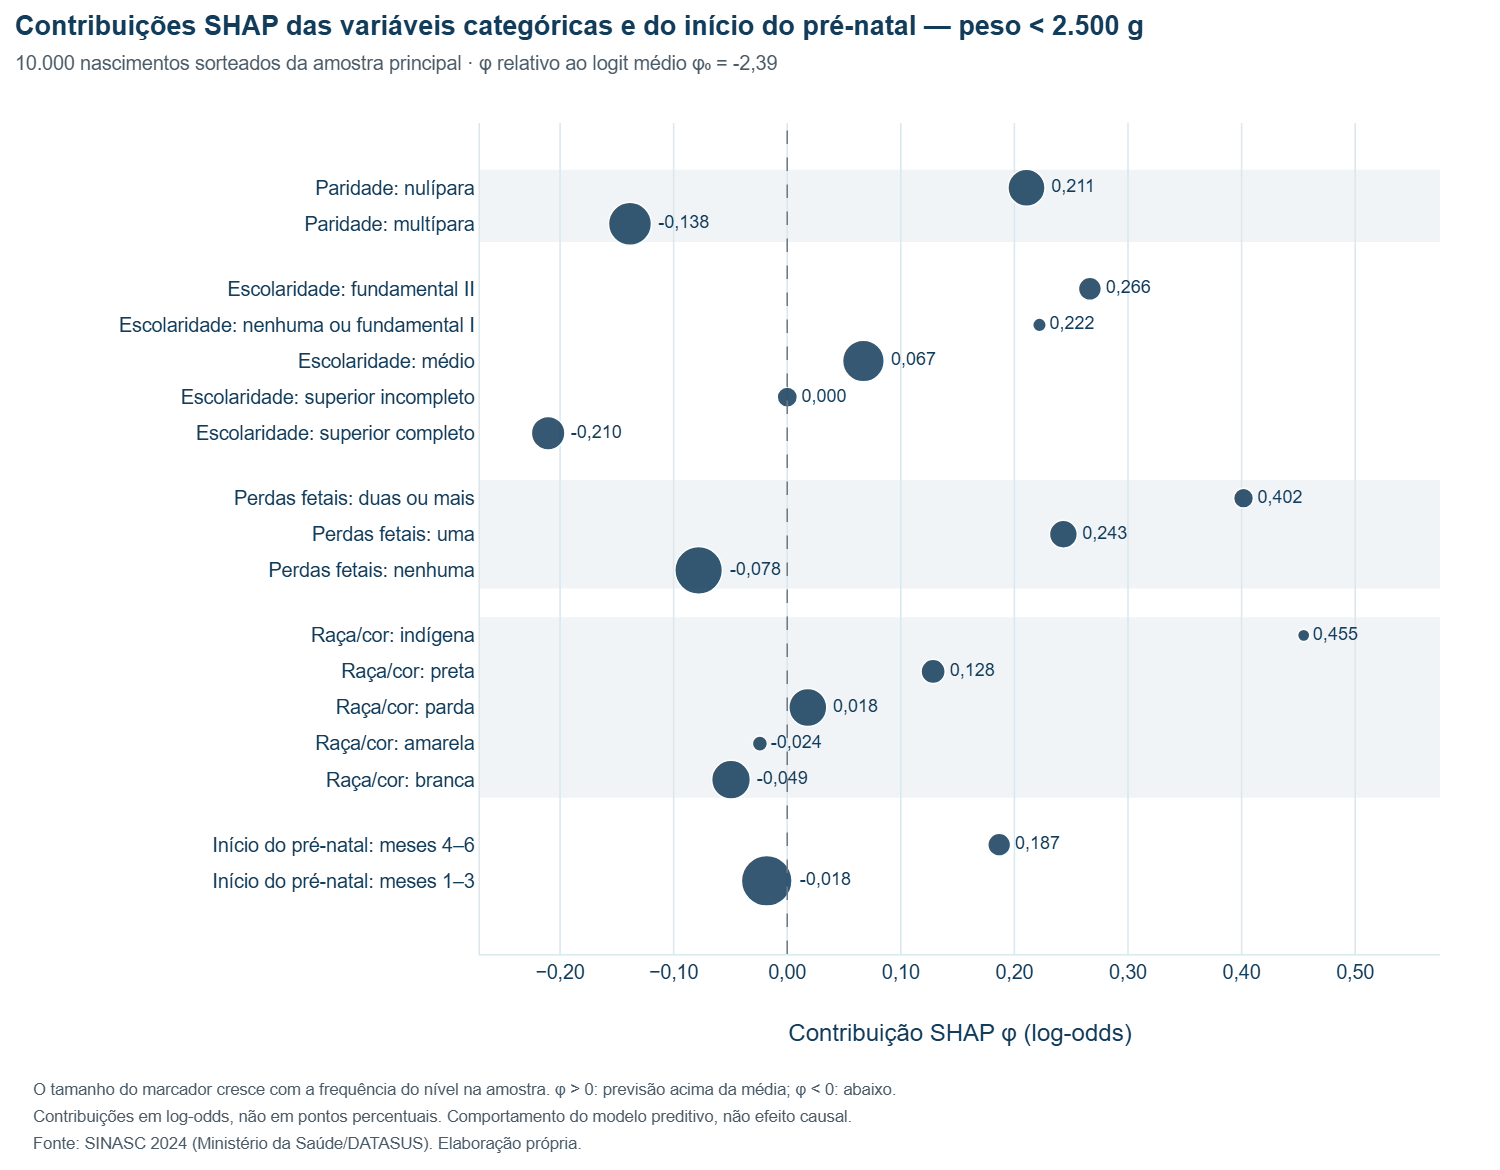

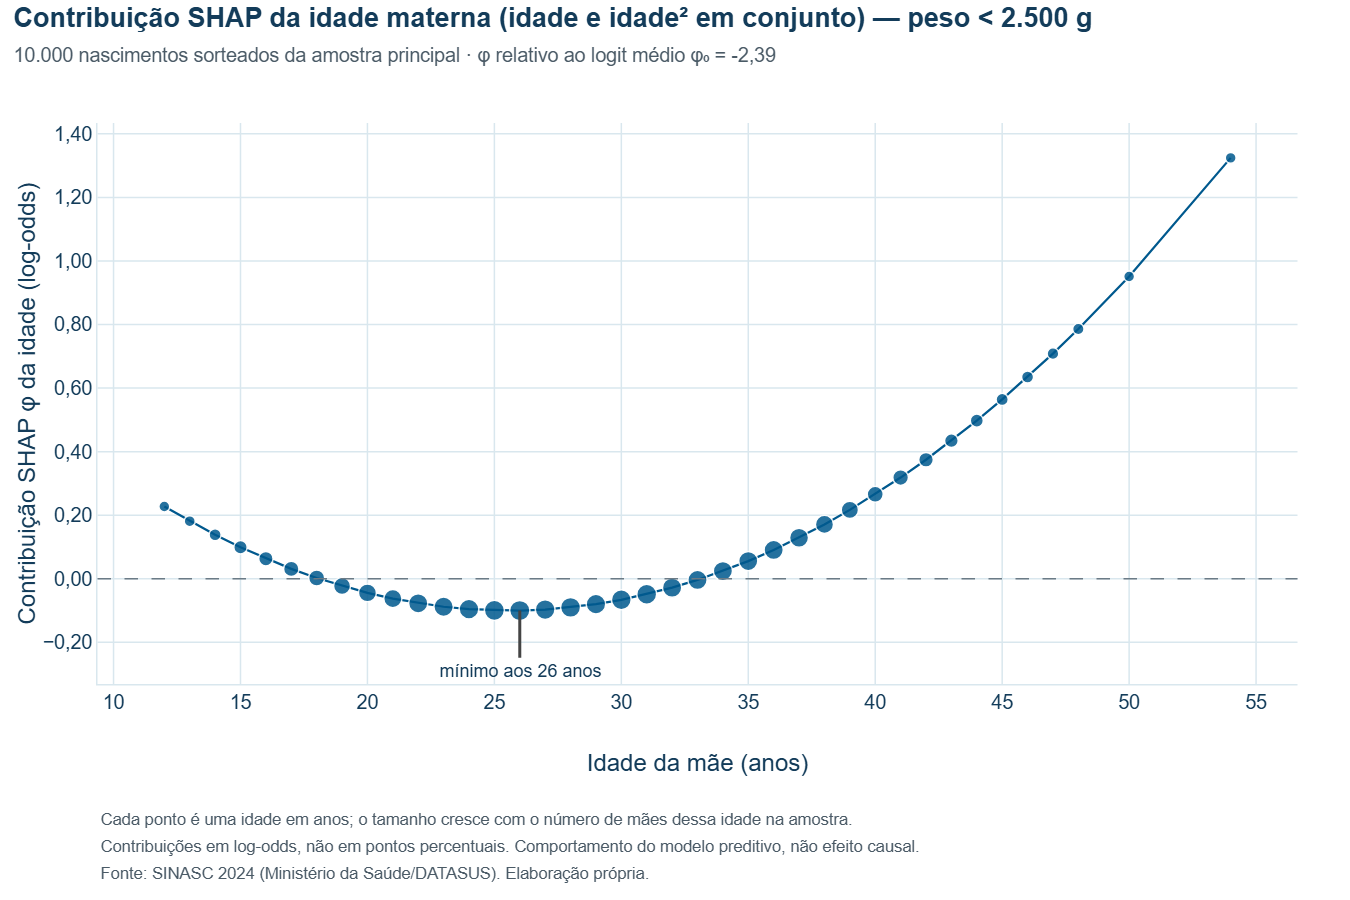

**Ordem de importância** (média de |φ| em log-odds). Peso < 2.500 g: paridade (0,167), escolaridade (0,125), perdas fetais (0,122), idade (0,093), raça/cor (0,045), início do pré-natal (X1) (0,033). Peso < 2.600 g: paridade (0,163), perdas fetais (0,112), escolaridade (0,111), idade (0,085), raça/cor (0,034), início do pré-natal (X1) (0,030); a mesma ordem, exceto escolaridade e perdas fetais, que trocam de posição. Na amostra principal inteira, a importância difere da amostra sorteada em no máximo 0,001 log-odds, e a ordem é a mesma nos dois desfechos.

Escolaridade e perdas fetais ficam quase empatadas (diferença, em log-odds, de 0,003 para peso < 2.500 g e de 0,001 para peso < 2.600 g). A ordem entre elas não deve ser lida como robusta.

Raça/cor e início do pré-natal (X1) ficam quase empatadas (diferença, em log-odds, de 0,004 para peso < 2.600 g). A ordem entre elas não deve ser lida como robusta.

**Paridade** teve a maior importância: nulípara (40,1% da amostra) contribui com φ = 0,211, e multípara (59,9%), com φ = -0,138. Os dois níveis são frequentes, e por isso a variável move muitas previsões.

**Início do pré-natal (X1)** ficou em 6º lugar entre as 6 variáveis: 91,4% das mães da amostra têm X1 = 1, com φ = -0,018, e 8,6% têm X1 = 0, com φ = 0,187. A OR do início do pré-natal mede associação condicional (seção 2). Aqui, como quase todas as mães estão no mesmo nível, a variável move pouco as previsões, o que é coerente com o ganho mínimo de AUC da seção 4.

**Idade:** a contribuição é mínima aos 26 anos (φ = -0,100) e cresce nos dois extremos: φ = -0,023 aos 19 anos (percentil 5 da amostra) e 0,266 aos 40 anos (percentil 95). 84% das mães têm |φ da idade| < 0,1.

**Níveis raros** podem ter contribuição individual alta e pouca importância global: raça/cor: indígena (0,18% da amostra, φ = 0,455).

**No conjunto**, as previsões ficam próximas do logit médio (φ₀ = -2,39): 90% dos logits previstos na amostra estão entre -2,79 e -1,96, ou seja, probabilidades de 5,8% a 12,3%. É a mesma limitação indicada pela ROC-AUC de 0,571. Esses resultados descrevem o comportamento preditivo da regressão logística ajustada: a variável mais importante é a que mais contribuiu para as previsões do modelo, não a causa do baixo peso. A importância SHAP também não equivale a significância estatística nem a relevância clínica.

In [11]:
# SHAP da regressão logística ajustada do desfecho (não do escore de propensão), na escala do logit (log-odds).
import shap
from src.interpretabilidade import (ROTULOS_GRUPOS, TAMANHO_AMOSTRA_SHAP, agrupar_contribuicoes, amostra_reprodutivel,
                                    contribuicao_por_nivel, contribuicoes_lineares, contribuicoes_shap,
                                    erro_reconstrucao, grupos_de_termos, importancia_global)
from src.graficos import COR_FAIXA
from src.logistica_desfecho import ROTULOS_NIVEIS, SEMENTE

posicoes_shap = amostra_reprodutivel(len(x_p6), TAMANHO_AMOSTRA_SHAP, SEMENTE)
x_shap = x_p6.iloc[posicoes_shap]
resultados_shap, importancias, importancias_universo, erros_shap = {}, {}, {}, {}
for rotulo in ORDEM_DESFECHOS:
    m = modelos_m3[rotulo]
    phi, base = contribuicoes_shap(m, x_shap, x_p6)                  # biblioteca SHAP; fundo = amostra principal inteira
    phi_exato, base_exato = contribuicoes_lineares(m, x_shap, x_p6)  # forma fechada, para conferência
    grupos = grupos_de_termos(phi.columns)
    agrupado = agrupar_contribuicoes(phi, grupos)
    phi_universo, _ = contribuicoes_lineares(m, x_p6, x_p6)
    importancias[rotulo] = importancia_global(agrupado)
    importancias_universo[rotulo] = importancia_global(agrupar_contribuicoes(phi_universo, grupos))
    logito = m.decision_function(x_shap)
    erros_shap[rotulo] = {"shap_vs_exato": float(np.abs((phi - phi_exato).to_numpy()).max()),
                          "base": abs(base - base_exato), "reconstrucao": erro_reconstrucao(phi, base, logito),
                          "agregacao": float(np.abs(agrupado.sum(axis=1) - phi.sum(axis=1)).max())}
    resultados_shap[rotulo] = {"base": base, "agrupado": agrupado, "logito": logito,
                               "niveis": contribuicao_por_nivel(agrupado, x_p6)}
print(f"SHAP conferido: shap {shap.__version__}, LinearExplainer (perturbação intervencional), escala log-odds. "
      f"Universo e fundo: amostra principal, {fmt(len(x_p6))} nascimentos; amostra de {fmt(len(x_shap))} sorteada sem "
      f"reposição (semente {SEMENTE}). Maior diferença entre a biblioteca e a decomposição exata, erro de reconstrução "
      f"do logit e erro da agregação: {max(max(e.values()) for e in erros_shap.values()):.1e}.")

CURTO = {X1: "início do pré-natal (X1)", "IDADE": "idade", "ESCOLARIDADE_MAE": "escolaridade",
         "RACA_COR_MAE": "raça/cor", "PARIDADE_CAT": "paridade", "PERDAS_FETAIS_CAT": "perdas fetais"}
ROTULO_NIVEL_GRUPO = {X1: "Início do pré-natal", "ESCOLARIDADE_MAE": "Escolaridade", "RACA_COR_MAE": "Raça/cor",
                      "PARIDADE_CAT": "Paridade", "PERDAS_FETAIS_CAT": "Perdas fetais"}
ordem_grupos = list(importancias["< 2.500 g"].index)
display(pd.DataFrame(
    {(f"Peso {r}", coluna): imp.loc[ordem_grupos].map(lambda v: fmt(v, 3)).to_numpy()
     for r in ORDEM_DESFECHOS for coluna, imp in [("amostra (10.000)", importancias[r]),
                                                  ("amostra principal inteira", importancias_universo[r])]},
    index=pd.Index([ROTULOS_GRUPOS[g] for g in ordem_grupos], name="Média de |φ| (log-odds)")))
NOTA_ESCALA = "Contribuições em log-odds, não em pontos percentuais. Comportamento do modelo preditivo, não efeito causal."

# ---- Figura: importância global
fig_imp = go.Figure()
for rotulo, cor in [("< 2.500 g", COR_REFERENCIA), ("< 2.600 g", COR_T1)]:
    v = importancias[rotulo].loc[ordem_grupos]
    fig_imp.add_bar(y=[ROTULOS_GRUPOS[g] for g in ordem_grupos], x=v, orientation="h", name=f"Peso ao nascer {rotulo}",
                    marker=dict(color=cor), text=[fmt(a, 3) for a in v], textposition="outside", cliponaxis=False,
                    textfont=dict(size=13),
                    hovertemplate="<b>%{y}</b><br>média de |φ| %{x:.3f} log-odds<extra>" + rotulo + "</extra>")
layout_academico(
    fig_imp, "Importância global das variáveis na regressão logística para baixo peso ao nascer",
    f"São Paulo (capital), 2024 · média de |φ| (SHAP, log-odds) em {fmt(len(x_shap))} nascimentos sorteados da amostra principal",
    notas=["Idade = idade + idade²; categóricas = soma dos seus indicadores, linha a linha, antes do valor absoluto.",
           NOTA_ESCALA, FONTE_SINASC_2024],
    nome_arquivo="nb06_shap_importancia", altura=560, margem_esquerda=250)
fig_imp.update_layout(barmode="group", bargap=0.25, bargroupgap=0.05,
                      legend=dict(orientation="h", x=0, y=1.02, yanchor="bottom"))
fig_imp.update_xaxes(title="Média de |φ| (log-odds)", range=[0, 1.18 * max(i.max() for i in importancias.values())],
                     tickformat=".2f")
fig_imp.update_yaxes(autorange="reversed")
exibir_plotly(fig_imp)

# ---- Figura D: contribuições por nível de X1 e das categóricas (peso < 2.500 g)
niveis = resultados_shap["< 2.500 g"]["niveis"]
base25 = resultados_shap["< 2.500 g"]["base"]
categoricos = niveis[niveis.grupo != "IDADE"].copy()
NIVEIS_X1 = {1: "meses 1–3", 0: "meses 4–6"}
categoricos["rotulo"] = [f"{ROTULO_NIVEL_GRUPO[g]}: {NIVEIS_X1[n] if g == X1 else ROTULOS_NIVEIS[g][n]}"
                         for g, n in zip(categoricos.grupo, categoricos.nivel)]
categoricos["ordem"] = categoricos.grupo.map({g: i for i, g in enumerate(ordem_grupos)})
categoricos = categoricos.sort_values(["ordem", "phi_medio"], ascending=[True, False]).reset_index(drop=True)
categoricos["y"] = np.arange(len(categoricos)) + 0.8 * categoricos.ordem.rank(method="dense").sub(1)
tamanho = lambda pct: 7 + 2.8 * np.sqrt(pct)
fig_cat = go.Figure()
fig_cat.add_scatter(
    x=categoricos.phi_medio, y=categoricos.y, mode="markers+text", showlegend=False,
    text=[fmt(v, 3) for v in categoricos.phi_medio], textposition="middle right", textfont=dict(size=12),
    marker=dict(size=tamanho(categoricos.pct), color=COR_TEXTO, opacity=0.85, line=dict(width=1, color="white")),
    customdata=np.c_[categoricos.rotulo, categoricos.n.map(fmt), categoricos.pct.map(lambda v: fmt(v, 1))],
    hovertemplate="<b>%{customdata[0]}</b><br>φ = %{x:.3f} log-odds<br>n %{customdata[1]} (%{customdata[2]}% da amostra)"
                  "<extra></extra>")
fig_cat.add_vline(x=0, line=dict(color=COR_REFERENCIA, dash="dash", width=1))
for _, grupo in categoricos.groupby("ordem"):   # faixas alternadas separam as variáveis
    if int(grupo.ordem.iloc[0]) % 2 == 0:
        fig_cat.add_hrect(y0=grupo.y.min() - 0.5, y1=grupo.y.max() + 0.5, fillcolor=COR_FAIXA, line_width=0, layer="below")
layout_academico(
    fig_cat, "Contribuições SHAP das variáveis categóricas e do início do pré-natal — peso < 2.500 g",
    f"{fmt(len(x_shap))} nascimentos sorteados da amostra principal · φ relativo ao logit médio φ₀ = {fmt(base25, 2)}",
    notas=["O tamanho do marcador cresce com a frequência do nível na amostra. φ > 0: previsão acima da média; φ < 0: abaixo.",
           NOTA_ESCALA, FONTE_SINASC_2024],
    nome_arquivo="nb06_shap_categoricas", largura=1000, altura=780, margem_esquerda=320)
fig_cat.update_yaxes(tickvals=categoricos.y, ticktext=categoricos.rotulo, autorange="reversed", showgrid=False)
fig_cat.update_xaxes(title="Contribuição SHAP φ (log-odds)", tickformat=".2f",
                     range=[categoricos.phi_medio.min() - 0.06, categoricos.phi_medio.max() + 0.12])
exibir_plotly(fig_cat)

# ---- Figura E: contribuição conjunta de idade e idade² (peso < 2.500 g)
idades = niveis[niveis.grupo == "IDADE"].astype({"nivel": float})
phi_idade = idades.set_index("nivel").phi_medio
fig_idade = go.Figure()
fig_idade.add_scatter(
    x=idades.nivel, y=idades.phi_medio, mode="lines+markers", showlegend=False, line=dict(color=COR_T1, width=1.5),
    marker=dict(size=tamanho(idades.pct), color=COR_T1, opacity=0.85, line=dict(width=1, color="white")),
    customdata=np.c_[idades.n.map(fmt), idades.pct.map(lambda v: fmt(v, 1))],
    hovertemplate="<b>%{x:.0f} anos</b><br>φ = %{y:.3f} log-odds<br>n %{customdata[0]} (%{customdata[1]}% da amostra)"
                  "<extra></extra>")
fig_idade.add_hline(y=0, line=dict(color=COR_REFERENCIA, dash="dash", width=1))
fig_idade.add_annotation(x=phi_idade.idxmin(), y=phi_idade.min(), text=f"mínimo aos {fmt(phi_idade.idxmin())} anos",
                         showarrow=True, arrowhead=0, ax=0, ay=40, font=dict(size=12, color=COR_TEXTO))
layout_academico(
    fig_idade, "Contribuição SHAP da idade materna (idade e idade² em conjunto) — peso < 2.500 g",
    f"{fmt(len(x_shap))} nascimentos sorteados da amostra principal · φ relativo ao logit médio φ₀ = {fmt(base25, 2)}",
    notas=["Cada ponto é uma idade em anos; o tamanho cresce com o número de mães dessa idade na amostra.",
           NOTA_ESCALA, FONTE_SINASC_2024],
    nome_arquivo="nb06_shap_idade", largura=900, altura=600)
fig_idade.update_xaxes(title="Idade da mãe (anos)", dtick=5)
fig_idade.update_yaxes(title="Contribuição SHAP φ da idade (log-odds)", tickformat=".2f")
exibir_plotly(fig_idade)

# ---- Interpretação gerada a partir dos números
imp25, imp26 = importancias["< 2.500 g"], importancias["< 2.600 g"]
def ordem_txt(imp):
    return ", ".join(f"{CURTO[g]} ({fmt(v, 3)})" for g, v in imp.items())
x1_niv = niveis[niveis.grupo == X1].set_index("nivel")
posicao_x1 = ordem_grupos.index(X1) + 1
topo = categoricos[categoricos.grupo == ordem_grupos[0]] if ordem_grupos[0] != "IDADE" else None
agr25 = resultados_shap["< 2.500 g"]["agrupado"]
idade_amostra = x_shap.IDADEMAE_NUM
p5_idade, p95_idade = (float(np.percentile(idade_amostra, q, method="lower")) for q in (5, 95))
raros = categoricos[(categoricos.pct < 1) & (categoricos.phi_medio.abs() >= 0.3)]
q5, q95 = np.percentile(resultados_shap["< 2.500 g"]["logito"], [5, 95])
diferenca_amostra = max(float((importancias[r] - importancias_universo[r]).abs().max()) for r in ORDEM_DESFECHOS)
ordem_igual_universo = all(list(importancias[r].index) == list(importancias_universo[r].index) for r in ORDEM_DESFECHOS)
empates = {}   # pares vizinhos com diferença < 0,005 log-odds, por desfecho
for r in ORDEM_DESFECHOS:
    itens = list(importancias[r].items())
    for (a, va), (b, vb) in zip(itens, itens[1:]):
        if va - vb < 0.005:
            empates.setdefault(frozenset((a, b)), {})[r] = va - vb
fora_do_lugar = [g for g, h in zip(imp25.index, imp26.index) if g != h]
if not fora_do_lugar:
    comparacao_ordem = "a mesma ordem"
elif len(fora_do_lugar) == 2 and list(imp26.index).index(fora_do_lugar[0]) == list(imp25.index).index(fora_do_lugar[1]):
    comparacao_ordem = f"a mesma ordem, exceto {CURTO[fora_do_lugar[0]]} e {CURTO[fora_do_lugar[1]]}, que trocam de posição"
else:
    comparacao_ordem = "ordem diferente em " + ", ".join(CURTO[g] for g in fora_do_lugar)
texto = [
    f"**Ordem de importância** (média de |φ| em log-odds). Peso < 2.500 g: {ordem_txt(imp25)}. Peso < 2.600 g: "
    f"{ordem_txt(imp26)}; {comparacao_ordem}. "
    f"Na amostra principal inteira, a importância difere da amostra sorteada em no máximo {fmt(diferenca_amostra, 3)} "
    f"log-odds, e a ordem {'é a mesma' if ordem_igual_universo else 'muda'} nos dois desfechos."]
for par, difs in empates.items():
    a, b = sorted(par, key=ordem_grupos.index)
    texto.append(f"{CURTO[a][0].upper() + CURTO[a][1:]} e {CURTO[b]} ficam quase empatadas (diferença, em log-odds, de "
                 + " e de ".join(f"{fmt(d, 3)} para peso {r}" for r, d in difs.items())
                 + "). A ordem entre elas não deve ser lida como robusta.")
if topo is not None:
    alto, baixo = topo.iloc[0], topo.iloc[-1]
    texto.append(f"**{CURTO[ordem_grupos[0]].capitalize()}** teve a maior importância: {alto.rotulo.split(': ')[1]} "
                 f"({fmt(alto.pct, 1)}% da amostra) contribui com φ = {fmt(alto.phi_medio, 3)}, e "
                 f"{baixo.rotulo.split(': ')[1]} ({fmt(baixo.pct, 1)}%), com φ = {fmt(baixo.phi_medio, 3)}."
                 + (" Os dois níveis são frequentes, e por isso a variável move muitas previsões."
                    if min(alto.pct, baixo.pct) >= 20 else ""))
texto.append(
    f"**Início do pré-natal (X1)** ficou em {posicao_x1}º lugar entre as {len(ordem_grupos)} variáveis: "
    f"{fmt(x1_niv.loc[1, 'pct'], 1)}% das mães da amostra têm X1 = 1, com φ = {fmt(x1_niv.loc[1, 'phi_medio'], 3)}, e "
    f"{fmt(x1_niv.loc[0, 'pct'], 1)}% têm X1 = 0, com φ = {fmt(x1_niv.loc[0, 'phi_medio'], 3)}. A OR do início do "
    "pré-natal mede associação condicional (seção 2). Aqui, como quase todas as mães estão no mesmo nível, a variável "
    "move pouco as previsões, o que é coerente com o ganho mínimo de AUC da seção 4.")
texto.append(
    f"**Idade:** a contribuição é mínima aos {fmt(phi_idade.idxmin())} anos (φ = {fmt(phi_idade.min(), 3)}) e cresce "
    f"nos dois extremos: φ = {fmt(phi_idade[p5_idade], 3)} aos {fmt(p5_idade)} anos (percentil 5 da amostra) e "
    f"{fmt(phi_idade[p95_idade], 3)} aos {fmt(p95_idade)} anos (percentil 95). "
    f"{fmt(100 * (agr25['IDADE'].abs() < 0.1).mean(), 0)}% das mães têm |φ da idade| < 0,1.")
if len(raros):
    texto.append("**Níveis raros** podem ter contribuição individual alta e pouca importância global: " + "; ".join(
        f"{r.rotulo.lower()} ({fmt(r.pct, 2)}% da amostra, φ = {fmt(r.phi_medio, 3)})" for r in raros.itertuples()) + ".")
texto.append(
    f"**No conjunto**, as previsões ficam próximas do logit médio (φ₀ = {fmt(base25, 2)}): 90% dos logits previstos na "
    f"amostra estão entre {fmt(q5, 2)} e {fmt(q95, 2)}, ou seja, probabilidades de {fmt(100 * expit(q5), 1)}% a "
    f"{fmt(100 * expit(q95), 1)}%. É a mesma limitação indicada pela ROC-AUC de "
    f"{fmt(metricas['< 2.500 g', 'M3']['roc_auc'], 3)}. Esses resultados descrevem o comportamento preditivo da regressão "
    "logística ajustada: a variável mais importante é a que mais contribuiu para as previsões do modelo, não a causa do "
    "baixo peso. A importância SHAP também não equivale a significância estatística nem a relevância clínica.")
display(Markdown("\n\n".join(texto)))

## 6. Limitações

- **Previsão, associação e causa:** AUC, average precision, Brier e calibração medem previsão; a OR mede associação condicional. Nenhuma das duas afasta o confundimento não medido do notebook 03 (renda, plano de saúde, tabagismo, acesso).
- **Temporalidade e seleção:**
  - mês de início e covariáveis são registrados no parto;
  - só entram nascidos vivos com peso entre 500 e 6.000 g;
  - os meses 7–9 selecionam gestações mais longas;
  - os 993 registros sem mês válido, quase todos sem consulta registrada, ficam fora também da amostra de sensibilidade.
- **Codificação:** "sem escolaridade" foi agrupada com fundamental I, e os 94 ignorados foram imputados pela moda (seção 2). A sensibilidade por casos completos não testa outras formas de tratar a ausência.
- **Medida:** 2.600 g não é ponto de corte padrão; o da OMS é < 2.500 g.
- **Incerteza:** os IC de Wald, de Welch e da média supõem nascimentos independentes.
- **Interpretabilidade:** os valores SHAP descrevem a regressão logística ajustada em 2024, na escala do logit, com os preditores tratados como independentes (perturbação intervencional).
  - Não têm IC.
  - Não indicam efeito causal nem relevância clínica.
  - A ordem entre variáveis com importâncias próximas não é robusta.
- **Validação:** a avaliação é retrospectiva, só com validação interna (validação cruzada em 2024), e não equivale a previsão clínica prospectiva nem a validação externa. A validação temporal e o bootstrap das métricas não foram realizados.

In [12]:
# Reconciliação: confere cálculo, ausência de vazamento e reprodutibilidade; nada exige significância.
assert len(sem_mes) == 993 and (sem_codigo, codigo_99, zero_consulta) == (889, 104, 910)
assert sem_codigo + codigo_99 == len(sem_mes) and len(p9) - len(p6) == 1_735
# Números citados no texto da seção 1.
escolaridade = p6.groupby("ESCOLARIDADE_MAE").agg(n=("Y_2500", "size"), casos=("Y_2500", "sum"))
assert (escolaridade.loc["0", "n"], escolaridade.loc["0", "casos"], escolaridade.loc["1", "n"]) == (33, 2, 692)
assert len(p6_cc) == len(p6) - 94 == 114_600 and fmt(100 * p6.loc[~completos, "Y_2500"].mean(), 1) == "12,8"
# Reprodução dos valores já validados da especificação principal, que não muda.
assert [or_ic(ors[r, "P6"].loc[X1]) for r in DESFECHOS] == ["0,83 (0,78 a 0,88)", "0,81 (0,76 a 0,87)"]
assert [or_ic(ors[r, "P9"].loc[X1]) for r in DESFECHOS] == ["0,85 (0,80 a 0,90)", "0,84 (0,78 a 0,89)"]
assert [fmt(metricas[r, "M3"]["roc_auc"], 3) for r in DESFECHOS] == ["0,565", "0,571"]
assert (fmt(welch["diferenca"]), fmt(welch["ic95_inf"]), fmt(welch["ic95_sup"])) == ("23", "12", "34")
assert int(p6.Y_2600.sum() - p6.Y_2500.sum()) == int(p6.peso_num.between(2500, 2599).sum())
assert sum(int(p6[c].eq("IGNORADO").sum()) for c in ["ESCOLARIDADE_MAE", "RACA_COR_MAE", "PERDAS_FETAIS_CAT"]) == 94
assert list(x_p6.columns) == list(PREDITORES_M3) and list(x_p9.columns) == list(PREDITORES_M3)
for chave, diag in diagnosticos.items():
    assert diag["gradiente_max"] < 1e-8 and np.isfinite(diag["condicao"]), chave
for chave, t in ors.items():
    assert np.isfinite(t.to_numpy()).all() and ((t.ic95_inf < t["or"]) & (t["or"] < t.ic95_sup)).all(), chave
for rotulo, v in bruta.items():
    assert abs(v["or_modelo"] / v["or_tabela"] - 1) < 1e-8 and abs(v["ep_modelo"] / v["ep_tabela"] - 1) < 1e-8, rotulo
for (rotulo, nome), p in previsoes.items():
    assert len(p) == len(p6) and np.isfinite(p).all() and ((p > 0) & (p < 1)).all(), (rotulo, nome)
for rotulo, dobra in dobras.items():
    assert sorted(np.unique(dobra)) == list(range(5)) and np.bincount(dobra).min() > len(p6) // 5 - 2, rotulo
for (rotulo, nome), m in metricas.items():
    assert 0 <= m["roc_auc"] <= 1 and 0 <= m["average_precision"] <= 1 and 0 <= m["brier"] <= 1, (rotulo, nome)
    # M0 prevê a prevalência de cada dobra de treino: AUC perto de 0,5 e inclinação indefinida.
    assert nome != "M0" or (abs(m["roc_auc"] - 0.5) < 0.01 and np.isnan(m["inclinacao_calibracao"]))
repetida, _ = prever_fora_da_amostra(construir_modelo(MODELOS["M3"]), x_p6, p6.Y_2600.to_numpy())
assert np.array_equal(repetida, previsoes["< 2.600 g", "M3"])
assert welch["ic95_inf"] < welch["diferenca"] < welch["ic95_sup"] and welch["n_a"] + welch["n_b"] == len(p6)
assert anova["gl1"] == 5 and anova["gl2"] > 0 and 0 <= anova["p"] <= 1
assert int(resumo.loc[[f"Mês {m}" for m in range(1, 7)], "n"].sum()) == len(p6)
assert int(resumo.loc["Meses 1–3", "n"]) == ESPERADO_P6["x1"]
assert int(resumo.loc["Sem mês válido (vazio ou 99)", "n"]) == 993
# Seções 1.1 e 4: equação e SHAP conferem cálculo e aditividade; nenhuma ordem de importância é exigida.
assert max(erros_equacao.values()) < 1e-9
for rotulo, erros in erros_shap.items():
    assert max(erros.values()) < 1e-9, (rotulo, erros)
    assert np.isfinite(resultados_shap[rotulo]["agrupado"].to_numpy()).all()
    assert sorted(importancias[rotulo].index) == sorted(importancias_universo[rotulo].index)
assert len(np.unique(posicoes_shap)) == len(x_shap) == TAMANHO_AMOSTRA_SHAP
assert np.array_equal(posicoes_shap, amostra_reprodutivel(len(x_p6), TAMANHO_AMOSTRA_SHAP, SEMENTE))
assert (resumo_m3.groupby("variavel").n.sum() == len(p6)).all()
print("Verificações do notebook 06 concluídas: populações iguais às do 03, preditores permitidos, ajustes no máximo "
      "de verossimilhança, OR bruta igual à da tabela 2×2, previsões fora da amostra completas e reprodutíveis, "
      "intervalos coerentes; equação reproduz o pipeline e SHAP reconstrói o logit.")

Verificações do notebook 06 concluídas: populações iguais às do 03, preditores permitidos, ajustes no máximo de verossimilhança, OR bruta igual à da tabela 2×2, previsões fora da amostra completas e reprodutíveis, intervalos coerentes; equação reproduz o pipeline e SHAP reconstrói o logit.
